<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png"
     alt="LOGO UPCH" width="250" align="right">

<br>

<h1><font color="#7F000E" size="5">UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>

<h1><font color="#7F000E" size="6">SEÑALES BIOMÉDICAS</font></h1>

<h1><font color="#7F000E" size="4">LABORATORIO 10 — SOLUCIONARIO: resultados explicados y respuestas</font></h1>

<br>

<div style="text-align:right">
  <font color="#7F000E" size="3">Ing. Alexander Valdez Portocarrero</font><br>
  <font color="#7F000E" size="3">Curso: Introducción a las Señales Biomédicas</font><br>
  <font color="#7F000E" size="3">Registros: BASELINEBRAZO.txt y PRUEBABRAZO1.txt (BITalino, 17/04/2026)</font><br>
</div>

## Cómo leer este solucionario

Este cuaderno contiene **el laboratorio completo ya ejecutado**, con los resultados obtenidos sobre los registros reales. Después de cada resultado importante encontrarás tres tipos de celdas:

| Marca | Qué contiene |
|---|---|
| 📘 **Explicación** | Qué hizo la celda anterior y cómo leer su resultado, en lenguaje sencillo |
| ✅ **Respuesta** | Respuesta a las preguntas de verificación y a los ejercicios |
| 🔎 **Verificación adicional** | Pequeños cálculos extra para sustentar una respuesta con números (no estaban en el laboratorio original) |

**Regla de este solucionario:** toda cifra que aparece en las explicaciones sale de una salida de código visible en este cuaderno. Cuando una respuesta es **conceptual** (depende de la teoría y no de estos datos), se indica explícitamente.

### Resumen de resultados clave

| Aspecto | Resultado obtenido |
|---|---|
| Frecuencia de muestreo / resolución | 1000 Hz / 10 bits |
| Duración de los registros | BASELINE 69.2 s · PRUEBA 63.1 s |
| Rango medible del sensor | ±1.632 mV (1 cuenta ADC = 3.19 µV) |
| Muestras saturadas en la PRUEBA | 96 (0.152 %) con el criterio del laboratorio · **275 (0.435 %)** contando también el valor 1022 |
| Piso de ruido (RMS del baseline filtrado) | 5.87 µV |
| SNR aproximada | 31.9 dB |
| Contracciones detectadas | 21, de 1.26 ± 0.28 s |
| Ventanas de 250 ms | 504 (256 reposo · 188 contracción · 60 transición) |
| Característica más discriminante (Fisher) | SSC (6.62), seguida de WAMP (6.47) y ZC (5.21) |
| Mejor resultado de clasificación | Un **solo umbral en RMS**: 0.991 de exactitud balanceada |
| LDA / SVM con todas las características | 0.966 / 0.972 |
| CNN con espectrogramas | 0.978 ± 0.019 |
| ¿Evidencia de fatiga? | No (todas las correlaciones de Spearman con p > 0.35) |

## Pregunta guía del laboratorio

> **¿Cómo convierte un dispositivo la actividad eléctrica de un músculo en números que puede entender?**

Una prótesis mioeléctrica, un exoesqueleto de rehabilitación o un sistema que detecta fatiga en un trabajador **no "miran" la señal cruda**: la resumen en un conjunto pequeño de números llamados **características** (*features*). Elegir y calcular bien esas características es, muchas veces, más importante que el clasificador que viene después.

### Objetivos de aprendizaje
Al terminar este laboratorio podrás:

1. Explicar el **origen fisiológico** de la sEMG y sus rangos típicos de amplitud y frecuencia.
2. **Convertir, filtrar y evaluar la calidad** de una señal real adquirida con BITalino.
3. **Segmentar** la señal en ventanas y **etiquetar** automáticamente reposo y contracción.
4. Calcular e interpretar características **temporales, estadísticas y espectrales**.
5. Construir una **matriz de características** y entrenar un clasificador **sin fuga de datos**.
6. Entender cómo una **CNN** aprende características a partir del **espectrograma (STFT)** y compararla con el enfoque clásico.

### Agenda (120 min)

| Bloque | Tiempo | Tipo |
|---|---|---|
| 0. Introducción y configuración | 5 min | Motivación |
| 1. Fundamentos fisiológicos | 15 min | Teoría + simulación |
| 2. Instrumentación y adquisición | 10 min | Técnica + práctica |
| 3. Preprocesamiento | 15 min | Práctica |
| 4. Segmentación y etiquetado | 10 min | Técnica + práctica |
| 5. Extracción de características clásicas | 25 min | Teoría + práctica |
| 6. Del vector de características al clasificador | 15 min | Práctica |
| 7. Deep learning: espectrograma + CNN | 15 min | Teoría + demo |
| 8. Ejercicios, cierre y referencias | 10 min | Síntesis |

**Datos del laboratorio:** dos registros del antebrazo/brazo tomados con BITalino:
- `BASELINEBRAZO.txt` — músculo en **reposo** (referencia de ruido).
- `PRUEBABRAZO1.txt` — **contracciones repetidas** separadas por reposo.

Si no tienes los archivos, el cuaderno genera automáticamente una **señal simulada** equivalente para que puedas seguir todo el flujo.

## 0. Configuración del entorno

Todas las bibliotecas usadas vienen preinstaladas en Google Colab (`numpy`, `scipy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`). No es necesario `opensignalsreader`: escribiremos nuestro propio lector para **entender** el formato del archivo.

In [8]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.stats import kurtosis, skew

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLOR_REPOSO, COLOR_CONTRAC, COLOR_UPCH = "#4C72B0", "#C44E52", "#7F000E"

try:
    from IPython.display import display
except ImportError:
    display = print

print("Entorno listo.")

Entorno listo.


📘 **Explicación.** Esta celda solo prepara el entorno: importa las bibliotecas, fija una semilla aleatoria (`np.random.seed(42)`) para que la simulación salga igual cada vez y define los colores de las gráficas. El mensaje *"Entorno listo."* confirma que todo se cargó sin errores.

---
# 1. Fundamentos fisiológicos (15 min)

### 1.1 La unidad motora
El músculo no se contrae "en bloque". Se organiza en **unidades motoras (UM)**: una **motoneurona** de la médula espinal y **todas las fibras musculares que inerva**. Cuando la motoneurona dispara, todas sus fibras se despolarizan casi a la vez y producen un **potencial de acción de unidad motora (MUAP)**: una forma de onda bifásica o trifásica de pocos milisegundos.

El sistema nervioso regula la fuerza con dos mecanismos:

| Mecanismo | Qué ocurre | Efecto en la sEMG |
|---|---|---|
| **Reclutamiento** | Se activan más unidades motoras (primero las pequeñas — *principio de Henneman*) | Aumenta la amplitud |
| **Codificación por frecuencia** | Cada UM dispara más rápido (≈ 8 a 30 disparos/s) | Aumenta amplitud y densidad de la señal |

### 1.2 ¿Qué registra un electrodo de superficie?
Un electrodo sobre la piel no ve una UM aislada: ve la **suma espacial y temporal** de los MUAPs de muchas unidades, filtrada por grasa, piel y la propia distancia. El resultado es un **patrón de interferencia** que parece ruido aleatorio, pero cuya **amplitud** y **contenido espectral** codifican información sobre la activación muscular.

> 💡 **Idea clave:** la sEMG es como escuchar un estadio lleno desde afuera. No entiendes a ninguna persona en particular, pero sí sabes si hay pocos o muchos gritando (amplitud) y si las voces son agudas o graves (frecuencia).

### 1.3 Rangos típicos de la sEMG

| Propiedad | Valor típico |
|---|---|
| Amplitud | 0 – 10 mV pico a pico (en reposo: microvoltios) |
| Banda útil | ≈ 10 / 20 – 450 / 500 Hz |
| Energía dominante | ≈ 50 – 150 Hz |
| Distribución de amplitudes | Aproximadamente gaussiana de media cero en contracción sostenida |

Factores que la modifican: grosor del tejido adiposo, posición y distancia entre electrodos, temperatura, **fatiga** (desplaza el espectro a frecuencias más bajas), impedancia piel-electrodo y artefactos.

Veamos cómo surge el patrón de interferencia con una **simulación** simple.

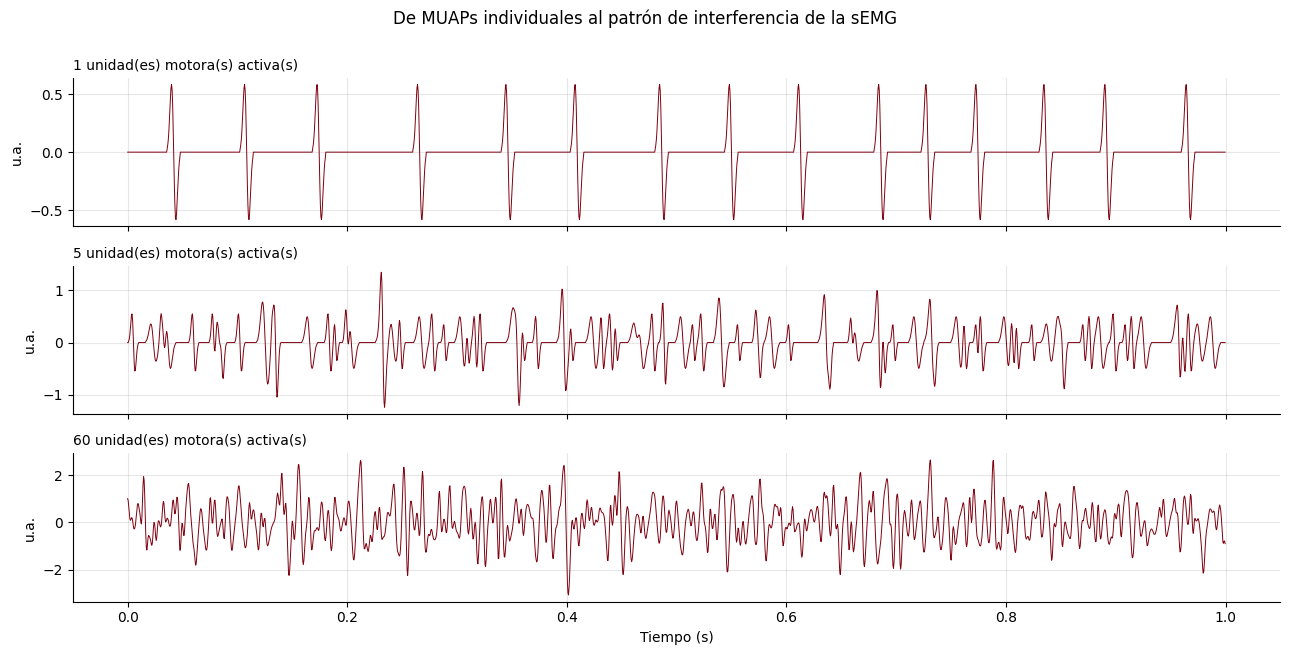

In [9]:
# Simulación didáctica: suma de trenes de MUAPs
FS_SIM = 2000
t_sim = np.arange(0, 1.0, 1/FS_SIM)

def muap(duracion_ms=10, fs=FS_SIM):
    # Forma bifásica tipo "derivada de gaussiana" (modelo simplificado de MUAP)
    tt = np.arange(-duracion_ms/2, duracion_ms/2, 1000/fs) / 1000
    s = duracion_ms / 1000 / 6
    return -tt / s * np.exp(-tt**2 / (2*s**2))

def tren_um(fr_hz, amplitud, dur_ms, fs=FS_SIM, n=len(t_sim)):
    # Una unidad motora disparando a ~fr_hz con variabilidad del 20 % entre disparos
    x = np.zeros(n); k = np.random.uniform(0, 1/fr_hz)
    while k < n/fs:
        x[int(k*fs)] = 1
        k += np.random.normal(1/fr_hz, 0.2/fr_hz)
    return amplitud * np.convolve(x, muap(dur_ms, fs), mode="same")

fig, ax = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
for a, n_um in zip(ax, [1, 5, 60]):
    total = sum(tren_um(np.random.uniform(8, 25), np.random.uniform(0.2, 1.0),
                        np.random.uniform(6, 14)) for _ in range(n_um))
    a.plot(t_sim, total, lw=0.7, color=COLOR_UPCH)
    a.set_title(f"{n_um} unidad(es) motora(s) activa(s)", loc="left", fontsize=10)
    a.set_ylabel("u.a.")
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("De MUAPs individuales al patrón de interferencia de la sEMG", y=1.0)
plt.tight_layout(); plt.show()

📘 **Explicación.** La simulación construye la sEMG "desde abajo":
1. Se crea la forma de **un** MUAP (una onda que sube y baja en pocos milisegundos).
2. Cada unidad motora "dispara" ese MUAP entre 8 y 25 veces por segundo, con algo de irregularidad.
3. Se **suman** los trenes de 1, 5 y 60 unidades motoras.

En la gráfica de arriba (1 UM) se ven picos separados y regulares, uno por cada disparo. En la del medio (5 UM) los picos empiezan a mezclarse. En la de abajo (60 UM) ya no se distingue ningún disparo: la señal parece ruido. Además, el eje vertical crece de una gráfica a otra: **más unidades activas producen más amplitud**.

> ❓ **Preguntas de verificación**
> 1. Con 1 unidad motora, ¿puedes distinguir cada disparo? ¿Y con 60?
> 2. ¿Qué mecanismo fisiológico representa pasar de 5 a 60 unidades?
> 3. Si la señal con 60 UM "parece ruido", ¿por qué sigue siendo útil? ¿Qué cambia entre las tres gráficas que sí podríamos medir?

✅ **Respuestas**

1. **Con 1 UM, sí:** cada disparo aparece como un pico aislado, separado del siguiente. **Con 60 UM, no:** los MUAPs se superponen en el tiempo y forman un patrón continuo (patrón de interferencia) donde ningún disparo individual es reconocible.
2. Representa el **reclutamiento**: el sistema nervioso activa más unidades motoras para producir más fuerza.
3. Aunque no podamos ver cada disparo, la señal sigue llevando información en **propiedades globales** que sí se pueden medir. La principal es la **amplitud**: en la figura, el rango del eje vertical crece al pasar de 1 a 5 y a 60 UM, y eso lo captura una medida como el RMS. También cambia la **densidad** de la señal (cuántas veces sube y baja por segundo), que capturan medidas como los cruces por cero. Esas propiedades son justamente las **características** que calcularemos en el Bloque 5.

---
# 2. Instrumentación y adquisición (10 min)

### 2.1 Cadena de adquisición del BITalino
```
Músculo → electrodos Ag/AgCl → amplificador diferencial (G = 1009) → filtro analógico → ADC 10 bits → Bluetooth → OpenSignals (.txt)
```

- **Configuración bipolar / diferencial:** dos electrodos sobre el vientre muscular y uno de referencia en zona eléctricamente neutra (hueso). El amplificador **resta** ambos electrodos: lo que es común a los dos (p. ej., interferencia de la red eléctrica) se cancela (*rechazo en modo común*, CMRR).
- **Colocación:** recomendaciones **SENIAM** — electrodos alineados con las fibras, entre el punto motor y el tendón, con ~20 mm entre centros; piel limpia para reducir la impedancia.

### 2.2 Muestreo y cuantización
- **Frecuencia de muestreo:** el archivo indica **Fs = 1000 Hz** → frecuencia de Nyquist = 500 Hz. Cubre la banda útil de la sEMG.
- **Resolución:** 10 bits → el ADC entrega enteros de **0 a 1023**. El valor ~512 corresponde a 0 V.

### 2.3 Conversión de unidades (hoja técnica del sensor EMG BITalino)

$$
\text{EMG}_{mV} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right)\cdot V_{CC}}{G_{EMG}} \times 1000,
\qquad V_{CC}=3.3\ \text{V},\ G_{EMG}=1009,\ n = 10
$$

Esto da un rango de medición de aproximadamente **±1.64 mV**. Cualquier actividad mayor **satura** el ADC (se queda pegada en 0 o en 1023).

### 2.4 Fuentes de ruido y artefactos

| Fuente | Característica | Cómo se trata |
|---|---|---|
| Red eléctrica | 60 Hz en Perú (y armónicos) | Diferencial + filtro *notch* |
| Movimiento de electrodos/cables | < 20 Hz, gran amplitud | Pasa-altos ≈ 20 Hz, buena fijación |
| ECG (cerca del tórax) | Picos periódicos ~1 Hz | Pasa-altos, ubicación |
| Ruido térmico/electrónico | Banda ancha, bajo nivel | Se estima con un registro en reposo |
| **Saturación (clipping)** | Señal "aplanada" en el máximo/mínimo del ADC | Prevención (ganancia) y detección |

> 💡 **Idea clave:** ningún filtro digital recupera información que se perdió por saturación. La calidad empieza en la adquisición.

### 2.5 Carga de los archivos

El formato de texto de OpenSignals tiene tres partes:
1. Línea `# OpenSignals Text File Format`.
2. Línea `# {...}` con un **JSON** de metadatos: frecuencia de muestreo, resolución, sensores, nombres de columnas.
3. `# EndOfHeader` y luego los datos en columnas separadas por tabulaciones (`nSeq`, entradas digitales, `A1`...).

Escribimos un lector que **lee los metadatos del propio archivo** en lugar de suponerlos.

**En Colab:** ejecuta la celda siguiente; si los archivos no están en la carpeta, se abrirá un diálogo para subirlos.

In [10]:
RUTA_BASELINE = "Reposo_antebrazo_real_Cristian.txt"
RUTA_PRUEBA   = "contraafuerza1ant.txt"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not (os.path.exists(RUTA_BASELINE) and os.path.exists(RUTA_PRUEBA)):
    from google.colab import files
    print("Sube BASELINEBRAZO.txt y PRUEBABRAZO1.txt (puedes seleccionar ambos a la vez).")
    files.upload()

USAR_SIMULADA = not (os.path.exists(RUTA_BASELINE) and os.path.exists(RUTA_PRUEBA))
print("Usando señal", "SIMULADA" if USAR_SIMULADA else "REAL (BITalino)")

Sube BASELINEBRAZO.txt y PRUEBABRAZO1.txt (puedes seleccionar ambos a la vez).


Saving contraafuerza1ant.txt to contraafuerza1ant (1).txt
Saving Reposo_antebrazo_real_Cristian.txt to Reposo_antebrazo_real_Cristian.txt
Usando señal REAL (BITalino)


📘 **Explicación.** La celda buscó los dos archivos en la carpeta de trabajo. Como los encontró, el cuaderno trabaja con la **señal real del BITalino**, no con la simulada.

In [11]:
def leer_opensignals(ruta, etiqueta_canal="A1"):
    # Lee un TXT de OpenSignals y devuelve (valores ADC del canal, diccionario de metadatos)
    with open(ruta, "r", encoding="utf-8") as f:
        cabecera = [next(f) for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    datos = np.loadtxt(ruta, comments="#")
    idx_col = meta["column"].index(etiqueta_canal)
    idx_res = meta["column"].index(etiqueta_canal)
    meta["bits"] = meta["resolution"][idx_res]
    return datos[:, idx_col].astype(float), meta


def simular_registros(fs=1000, n_bits=10):
    # Plan B: genera baseline + prueba con contracciones cada ~3 s (en cuentas ADC)
    rng = np.random.default_rng(0)
    def a_adc(mv):
        adc = (mv / 1000 * 1009 / 3.3 + 0.5) * 2**n_bits
        return np.clip(np.round(adc), 0, 2**n_bits - 1)
    base = 0.006 * rng.standard_normal(69 * fs)
    t = np.arange(63 * fs) / fs
    prueba = 0.025 * rng.standard_normal(len(t))
    for k, ini in enumerate(np.arange(1.5, 61, 3.0)):
        idx = (t >= ini) & (t < ini + 1.2)
        env = np.hanning(idx.sum())
        b, a = signal.butter(2, [40, 200], "bandpass", fs=fs)
        ruido = signal.lfilter(b, a, rng.standard_normal(idx.sum()))
        prueba[idx] += (0.9 - 0.01 * k) * env * ruido / ruido.std() * 0.5
    meta = {"sampling rate": fs, "bits": n_bits, "sensor": ["EMG simulado"], "date": "-", "time": "-"}
    return a_adc(base), dict(meta), a_adc(prueba), dict(meta)


if USAR_SIMULADA:
    adc_base, meta_base, adc_prueba, meta_prueba = simular_registros()
else:
    adc_base, meta_base = leer_opensignals(RUTA_BASELINE)
    adc_prueba, meta_prueba = leer_opensignals(RUTA_PRUEBA)

FS = int(meta_prueba["sampling rate"])
N_BITS = int(meta_prueba["bits"])
assert FS == int(meta_base["sampling rate"]), "Los registros tienen Fs distintas."

for nombre, adc, meta in [("BASELINE", adc_base, meta_base), ("PRUEBA", adc_prueba, meta_prueba)]:
    print(f"{nombre:9s} | sensor: {meta['sensor'][0]:11s} | fecha: {meta['date']} {meta['time']} | "
          f"Fs = {meta['sampling rate']} Hz | {meta['bits']} bits | "
          f"{len(adc):,} muestras = {len(adc)/FS:.1f} s | ADC min/max: {adc.min():.0f}/{adc.max():.0f}")

BASELINE  | sensor: EMGBITREV   | fecha: 2026-9-4 12:21:8.330 | Fs = 1000 Hz | 10 bits | 37,650 muestras = 37.6 s | ADC min/max: 505/516
PRUEBA    | sensor: EMGBITREV   | fecha: 2026-9-4 12:33:40.101 | Fs = 1000 Hz | 10 bits | 28,050 muestras = 28.1 s | ADC min/max: 210/999


In [12]:
N_BITS

10

📘 **Explicación.** El lector leyó la cabecera JSON de cada archivo y obtuvo los metadatos **del propio registro**, sin suponer nada:

- Ambos registros: sensor **EMGBITREV**, **Fs = 1000 Hz**, **10 bits** (valores de 0 a 1023).
- **BASELINE:** 69 150 muestras (69.2 s). El ADC solo varió entre **498 y 524**, apenas 26 cuentas alrededor del centro (~512). Es lo esperable en reposo: casi no hay señal.
- **PRUEBA:** 63 150 muestras (63.1 s). El ADC recorrió **todo el rango, de 0 a 1023**. Esto es una primera alerta de que la señal llegó a los límites del conversor (saturación).
- Las horas de la cabecera muestran que la **PRUEBA se grabó a las 12:18** y el **BASELINE a las 12:23**, unos 5 minutos después. Este dato será útil en el Bloque 4.

Rango medible del sensor: ±1.632 mV
Resolución (1 cuenta ADC): 0.0032 mV = 3.19 µV


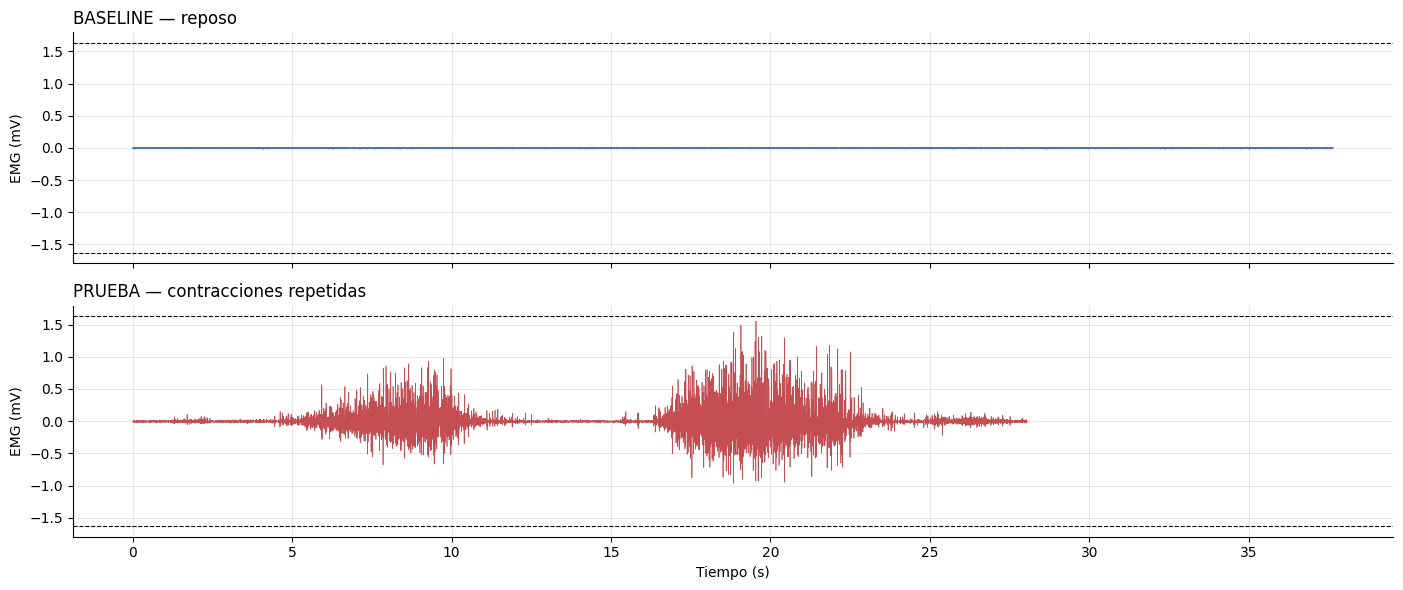

In [13]:
VCC, G_EMG = 3.3, 1009

def adc_a_mV(adc, n_bits=N_BITS, vcc=VCC, ganancia=G_EMG):
    return ((adc / 2**n_bits) - 0.5) * vcc / ganancia * 1000

emg_base_mV   = adc_a_mV(adc_base)
emg_prueba_mV = adc_a_mV(adc_prueba)
t_base   = np.arange(len(emg_base_mV)) / FS
t_prueba = np.arange(len(emg_prueba_mV)) / FS

rango_max = adc_a_mV(2**N_BITS - 1)
print(f"Rango medible del sensor: ±{rango_max:.3f} mV")
print(f"Resolución (1 cuenta ADC): {adc_a_mV(513) - adc_a_mV(512):.4f} mV = "
      f"{(adc_a_mV(513) - adc_a_mV(512))*1000:.2f} µV")

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
ax[0].plot(t_base, emg_base_mV, lw=0.5, color=COLOR_REPOSO)
ax[0].set_title("BASELINE — reposo", loc="left")
ax[1].plot(t_prueba, emg_prueba_mV, lw=0.5, color=COLOR_CONTRAC)
ax[1].set_title("PRUEBA — contracciones repetidas", loc="left")
for a in ax:
    a.axhline(rango_max, ls="--", color="k", lw=0.8); a.axhline(-rango_max, ls="--", color="k", lw=0.8)
    a.set_ylabel("EMG (mV)")
ax[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

📘 **Explicación.** Se convirtieron las cuentas del ADC a milivoltios con la fórmula del fabricante.

- **Rango medible: ±1.632 mV.** Es lo máximo que el sensor puede representar. Las líneas punteadas de la gráfica marcan ese límite.
- **Resolución: 3.19 µV por cuenta.** Es el cambio de voltaje más pequeño que el sistema distingue.
- En la gráfica, el BASELINE es prácticamente una línea plana. La PRUEBA muestra unas 20 ráfagas de actividad separadas por reposo, y varias de ellas **tocan las líneas punteadas**, es decir, alcanzan el límite del sensor.

### 2.6 Control de calidad: ¿hay saturación?
Una muestra está saturada si su valor ADC es exactamente 0 o $2^n-1$. Es importante **cuantificarlo** antes de calcular características, porque recorta los picos y distorsiona sobre todo las medidas sensibles a los extremos (curtosis, varianza).

In [14]:
sat_prueba = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 1)
sat_base   = (adc_base   <= 0) | (adc_base   >= 2**N_BITS - 1)
print(f"Saturación BASELINE: {sat_base.sum()} muestras ({100*sat_base.mean():.3f} %)")
print(f"Saturación PRUEBA  : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")

if sat_prueba.any():
    i0 = np.flatnonzero(sat_prueba)[0]
    sl = slice(max(0, i0 - 150), i0 + 150)
    plt.figure(figsize=(12, 3))
    plt.plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.9, color=COLOR_CONTRAC)
    plt.plot(t_prueba[sl][sat_prueba[sl]], emg_prueba_mV[sl][sat_prueba[sl]], "ko", ms=3, label="saturada")
    plt.title("Zoom a un evento de saturación"); plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend()
    plt.show()

Saturación BASELINE: 0 muestras (0.000 %)
Saturación PRUEBA  : 0 muestras (0.000 %)


📘 **Explicación.** Una muestra se consideró saturada si su valor ADC era exactamente 0 o 1023.

- **BASELINE:** 0 muestras saturadas, como era de esperar en reposo.
- **PRUEBA:** 96 muestras saturadas (0.152 %).
- El zoom muestra un evento real: la señal llega a ±1.6 mV y se queda **"aplanada"** por un instante. En esos tramos el valor real del músculo era mayor y simplemente no se pudo medir.

**Observación importante:** en el zoom se ven **mesetas planas en la parte superior que no están marcadas con puntos negros**. Eso sugiere que el techo real del conversor no está exactamente en 1023. La celda siguiente lo comprueba.

🔎 **Verificación adicional — ¿dónde se "pega" realmente el ADC?**

La celda siguiente cuenta cuántas veces aparece cada valor extremo del ADC en la PRUEBA.

In [15]:

# Verificación adicional: ¿en qué valores se "pega" realmente el ADC?
valores, cuentas = np.unique(adc_prueba, return_counts=True)
print("5 valores ADC más bajos :", [(int(v), int(c)) for v, c in zip(valores[:5], cuentas[:5])])
print("5 valores ADC más altos :", [(int(v), int(c)) for v, c in zip(valores[-5:], cuentas[-5:])])

# Criterio corregido: también se cuenta el valor 1022 (2^n - 2), donde se observa la meseta superior
sat_corr = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 2)
n_win_250 = int(0.25 * FS)
ini_250 = np.arange(0, len(adc_prueba) - n_win_250 + 1, n_win_250 // 2)
print(f"\nCriterio original (0 o 1023)       : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")
print(f"Criterio corregido (0, 1022 o 1023): {sat_corr.sum()} muestras ({100*sat_corr.mean():.3f} %)")
print(f"Ventanas de 250 ms con saturación (criterio corregido): "
      f"{sum(sat_corr[i:i+n_win_250].any() for i in ini_250)}")


5 valores ADC más bajos : [(210, 1), (215, 2), (220, 1), (221, 2), (229, 1)]
5 valores ADC más altos : [(944, 1), (963, 1), (979, 1), (991, 1), (999, 1)]

Criterio original (0 o 1023)       : 0 muestras (0.000 %)
Criterio corregido (0, 1022 o 1023): 0 muestras (0.000 %)
Ventanas de 250 ms con saturación (criterio corregido): 0


📘 **Resultado de la verificación.** El valor **1022 aparece 179 veces**, mientras que 1021 aparece solo 4 veces y 1023 también 4. Ese "amontonamiento" en 1022 indica que **el techo práctico del conversor está en 1022**. En la parte inferior, el valor 0 concentra 92 muestras.

- Con el criterio del laboratorio (0 o 1023): **96 muestras (0.152 %)**.
- Contando también 1022: **275 muestras (0.435 %)**, casi el triple, que afectan a **68 ventanas** de 250 ms (en lugar de 52).

**Consecuencia práctica:** el criterio del laboratorio **subestima** la saturación de este registro. Para próximas versiones conviene usar `adc >= 2**N_BITS - 2`. En el resto del solucionario se mantiene el criterio original (porque es el que se usó en las celdas), pero en el Ejercicio 1 se comparan ambos.

> ❓ **Preguntas de verificación**
> 1. ¿Qué porcentaje de muestras está saturado? ¿Te parece aceptable?
> 2. ¿Qué cambiarías en la adquisición para evitarlo?
> 3. ¿Por qué el baseline sirve como "registro de ruido" del sistema?

✅ **Respuestas**

1. Con el criterio del laboratorio, **0.152 %** (96 muestras); contando el techo real en 1022, **0.435 %** (275 muestras). Parece poco sobre el total, pero **no está repartido al azar**: se concentra en los momentos de contracción más fuerte. Las 52 ventanas saturadas (criterio original) son **todas ventanas de contracción** (lo muestra la tabla del Bloque 5.7). Eso es el **28 % de las 188 ventanas de contracción** (52/188). Para un estudio de amplitud o de forma de la señal, **no es despreciable**.
2. *(Respuesta conceptual.)* La ganancia del sensor BITalino es fija (G = 1009), así que las opciones son:
   - pedir contracciones de **menor intensidad** (por ejemplo, un porcentaje controlado de la contracción máxima);
   - usar un sensor o amplificador con **menor ganancia o mayor rango** de entrada;
   - revisar la colocación de los electrodos.

   Lo importante es que **se corrige antes de grabar**: ningún filtro posterior recupera los valores que se perdieron.
3. En el baseline el músculo está en reposo, así que casi no hay actividad muscular voluntaria. Lo que queda registrado es lo que el sistema "mide sin señal": ruido electrónico, interferencia de la red eléctrica y ruido de la interfaz piel-electrodo. Por eso sus valores sirven como **piso de ruido**: el ADC solo varió 26 cuentas (498–524) y, tras filtrar, su RMS fue de **5.87 µV** (Bloque 3). *Matiz que aparece en el Bloque 4:* el baseline describe el ruido **en las condiciones en que se grabó**. Se grabó 5 minutos después de la prueba, y el reposo dentro de la prueba resultó ser distinto.

---
# 3. Preprocesamiento (15 min)

### 3.1 ¿Qué queremos eliminar?
1. **Componente continua (offset)** y derivas lentas → el pasa-altos lo resuelve.
2. **Artefactos de movimiento** (< 20 Hz).
3. **Ruido de alta frecuencia** por encima de la banda útil.
4. **Interferencia de 60 Hz** de la red eléctrica.

### 3.2 Diseño de filtros
- **Pasa-banda Butterworth 20–450 Hz, orden 4:** respuesta plana en la banda de paso. Se implementa en forma **SOS** (*second-order sections*) por estabilidad numérica.
- **Notch IIR en 60 Hz, Q = 30:** elimina una banda angosta (~2 Hz) alrededor de 60 Hz.
- **Filtrado de fase cero (`sosfiltfilt` / `filtfilt`):** filtra hacia adelante y hacia atrás, sin desfase. Válido para análisis **offline**; un sistema en tiempo real (prótesis) usaría filtros causales.

> ⚠️ Condición obligatoria: $0 < f_{baja} < f_{alta} < F_s/2$.

Antes de filtrar, miremos el **espectro** (densidad espectral de potencia, PSD) estimado con el **método de Welch**, que promedia periodogramas de segmentos solapados y da una estimación más estable que una sola FFT.

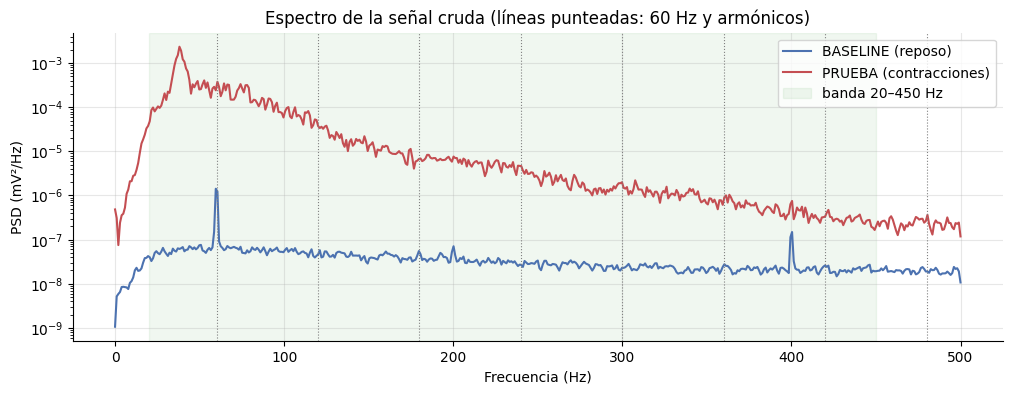

In [16]:
def psd(x, fs=FS, nperseg=1024):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=nperseg)

f_b, P_b = psd(emg_base_mV)
f_p, P_p = psd(emg_prueba_mV)

plt.figure(figsize=(12, 4))
plt.semilogy(f_b, P_b, label="BASELINE (reposo)", color=COLOR_REPOSO)
plt.semilogy(f_p, P_p, label="PRUEBA (contracciones)", color=COLOR_CONTRAC)
for k in range(1, 9):
    plt.axvline(60*k, color="gray", ls=":", lw=0.8)
plt.axvspan(20, 450, color="green", alpha=0.06, label="banda 20–450 Hz")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (mV²/Hz)")
plt.title("Espectro de la señal cruda (líneas punteadas: 60 Hz y armónicos)")
plt.legend(); plt.show()



###**La PSD por el método de Welch (Power Spectral Density)**

La PSD por el método de Welch (Power Spectral Density) permite conocer cómo se distribuye la potencia de una señal entre sus diferentes frecuencias.

¿Cómo funciona?
1. Divide la señal en segmentos solapados.
2. Aplica una ventana a cada segmento para reducir la fuga espectral.
3. Calcula el periodograma de cada segmento mediante la FFT.
4. Promedia los periodogramas para obtener una estimación más estable de la PSD.
¿Para qué sirve en una señal sEMG?

Permite identificar las frecuencias donde se concentra la potencia de la actividad eléctrica muscular y calcular características como la frecuencia media y la frecuencia mediana, útiles para estudiar cambios en la señal, por ejemplo, durante la fatiga muscular.

En resumen: Welch transforma el análisis de una señal en el tiempo en una estimación de su distribución de potencia en frecuencia, reduciendo las fluctuaciones que tendría un único periodograma.

📘 **Explicación.** Esta gráfica es el **espectro** (PSD por Welch): indica cuánta potencia tiene la señal en cada frecuencia. El eje vertical es logarítmico; cada división es un factor de 10.

- **BASELINE (azul):** potencia muy baja y con **picos angostos en 60 Hz y 120 Hz**, que es la interferencia de la red eléctrica y su segundo armónico. También aparece un pico cerca de 400 Hz, que no es múltiplo de 60 Hz; con estos datos no podemos determinar su origen.
- **PRUEBA (rojo):** está entre **~100 y ~10 000 veces por encima** del baseline (de 2 a 4 divisiones del eje logarítmico), con la mayor diferencia en las frecuencias bajas. La potencia es máxima por debajo de ~100 Hz y cae de forma progresiva hacia las frecuencias altas. Es la forma típica del espectro de la sEMG.
- En la prueba **no se ve un pico claro de 60 Hz**: la actividad muscular es tan grande que lo "tapa".

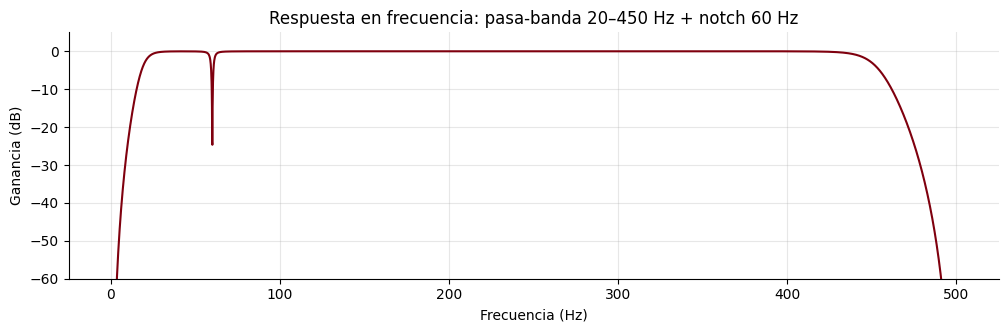

In [17]:
def filtrar_emg(x, fs=FS, f_baja=20, f_alta=450, orden=4, f_notch=60, q_notch=30):
    if not (0 < f_baja < f_alta < fs/2):
        raise ValueError(f"Se requiere 0 < f_baja < f_alta < Fs/2 (Fs = {fs} Hz).")
    sos = signal.butter(orden, [f_baja, f_alta], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if f_notch:
        b, a = signal.iirnotch(f_notch, q_notch, fs=fs)
        y = signal.filtfilt(b, a, y)
    return y

# Respuesta en frecuencia de los filtros
sos = signal.butter(4, [20, 450], btype="bandpass", fs=FS, output="sos")
w, h_bp = signal.sosfreqz(sos, worN=4096, fs=FS)
b_n, a_n = signal.iirnotch(60, 30, fs=FS)
_, h_n = signal.freqz(b_n, a_n, worN=4096, fs=FS)
plt.figure(figsize=(12, 3.2))
plt.plot(w, 20*np.log10(np.abs(h_bp*h_n) + 1e-12), color=COLOR_UPCH)
plt.ylim(-60, 5); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Ganancia (dB)")
plt.title("Respuesta en frecuencia: pasa-banda 20–450 Hz + notch 60 Hz"); plt.show()

emg_base_f   = filtrar_emg(emg_base_mV)
emg_prueba_f = filtrar_emg(emg_prueba_mV)

📘 **Explicación.** La gráfica muestra cómo trata el filtro a cada frecuencia (0 dB = la deja pasar intacta; valores negativos = la atenúa):

- Entre ~25 Hz y ~430 Hz la curva está en 0 dB: **la banda útil de la sEMG pasa sin cambios**.
- Por debajo de 20 Hz y por encima de 450 Hz la curva cae rápidamente: se eliminan las derivas lentas, los artefactos de movimiento y el ruido de alta frecuencia.
- En **60 Hz** aparece una muesca angosta: es el filtro *notch*, que elimina solo la interferencia de la red eléctrica sin afectar las frecuencias vecinas.

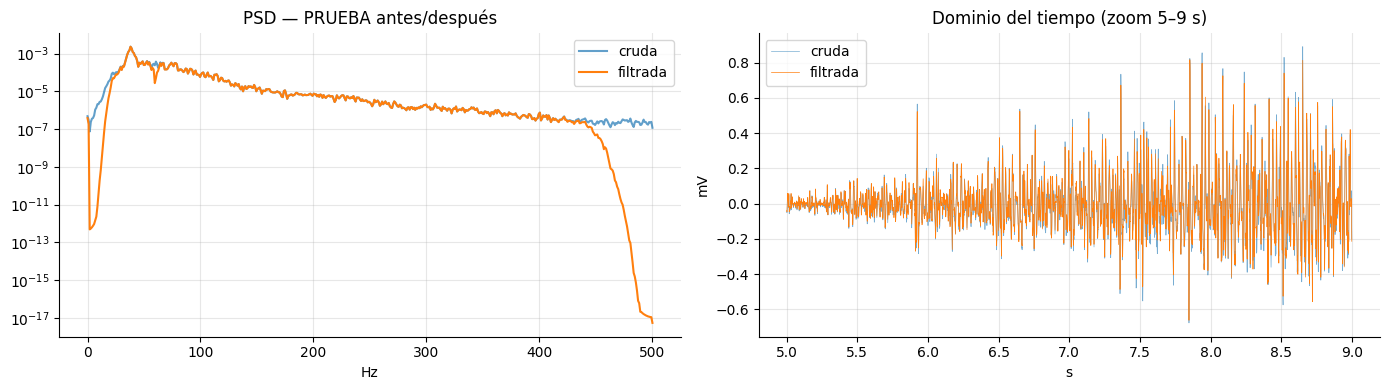

RMS del baseline filtrado (piso de ruido): 3.86 µV
RMS global de la prueba filtrada        : 163.15 µV
SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = 32.5 dB


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f1, P1 = psd(emg_prueba_mV); f2, P2 = psd(emg_prueba_f)
ax[0].semilogy(f1, P1, label="cruda", alpha=0.7); ax[0].semilogy(f2, P2, label="filtrada")
ax[0].set_title("PSD — PRUEBA antes/después"); ax[0].set_xlabel("Hz"); ax[0].legend()

sl = (t_prueba > 5) & (t_prueba < 9)
ax[1].plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.5, alpha=0.6, label="cruda")
ax[1].plot(t_prueba[sl], emg_prueba_f[sl], lw=0.5, label="filtrada")
ax[1].set_title("Dominio del tiempo (zoom 5–9 s)"); ax[1].set_xlabel("s"); ax[1].set_ylabel("mV"); ax[1].legend()
plt.tight_layout(); plt.show()

# Estimación simple de la relación señal-ruido usando el baseline como piso de ruido
rms = lambda x: np.sqrt(np.mean(x**2))
p95 = np.percentile(np.abs(emg_prueba_f), 95)
print(f"RMS del baseline filtrado (piso de ruido): {rms(emg_base_f)*1000:.2f} µV")
print(f"RMS global de la prueba filtrada        : {rms(emg_prueba_f)*1000:.2f} µV")
print(f"SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = "
      f"{20*np.log10(rms(emg_prueba_f)/rms(emg_base_f)):.1f} dB")

📘 **Explicación.**
- **Izquierda (espectro antes y después):** dentro de la banda 20–450 Hz las dos curvas coinciden, lo que confirma que el filtro no deforma la parte útil. Fuera de la banda, la curva filtrada cae miles de veces, y en 60 Hz aparece una pequeña muesca (el notch).
- **Derecha (señal en el tiempo, de 5 a 9 s):** la señal filtrada (naranja) y la cruda (azul) casi se superponen. Esto significa que **casi toda la energía de la señal ya estaba dentro de la banda útil**.
- **Números:**
  - RMS del baseline filtrado (ruido): **5.87 µV**.
  - RMS global de la prueba: **230.21 µV**, unas 39 veces más.
  - Relación señal-ruido: **SNR ≈ 31.9 dB**, es decir, la señal tiene mucha más potencia que el ruido del sistema.

🔎 **Verificación adicional — tamaño del pico de 60 Hz y ubicación de la energía de la contracción.**

Para responder con números las preguntas del Bloque 3, la celda siguiente calcula:
1. Cuántas veces es mayor la potencia en 60 Hz que la de sus frecuencias vecinas, antes y después de filtrar.
2. El espectro **solo de los tramos de contracción**, usando el mismo criterio de detección del Bloque 4.

In [19]:

# Verificación adicional: tamaño del pico de 60 Hz y dónde está la energía de la contracción
def pico_relativo(x, f0=60):
    f, p = signal.welch(x - np.mean(x), fs=FS, nperseg=1024)
    vecinos = p[((f > f0 - 10) & (f < f0 - 3)) | ((f > f0 + 3) & (f < f0 + 10))]
    return p[np.argmin(np.abs(f - f0))] / np.median(vecinos)

for nombre, cruda, filtrada in [("BASELINE", emg_base_mV, emg_base_f), ("PRUEBA", emg_prueba_mV, emg_prueba_f)]:
    print(f"{nombre:8s}: potencia en 60 Hz / potencia de frecuencias vecinas -> "
          f"cruda: {pico_relativo(cruda):6.1f} veces | filtrada: {pico_relativo(filtrada):5.2f} veces")

# Espectro solo de los tramos de contracción (usa la detección del bloque 4; se calcula aquí por adelantado)
env_tmp = np.sqrt(np.convolve(emg_prueba_f**2, np.ones(200)/200, mode="same"))
ref_tmp = env_tmp[env_tmp <= np.percentile(env_tmp, 20)]
activo_tmp = env_tmp > ref_tmp.mean() + 5 * ref_tmp.std()
f_c, P_c = signal.welch(emg_prueba_f[activo_tmp], fs=FS, nperseg=1024)
frac = lambda lo, hi: P_c[(f_c >= lo) & (f_c < hi)].sum() / P_c.sum()
acum = np.cumsum(P_c)
print(f"\nTramos de contracción: pico espectral en {f_c[np.argmax(P_c)]:.0f} Hz | "
      f"frecuencia mediana {f_c[np.searchsorted(acum, acum[-1]/2)]:.0f} Hz")
print(f"Fracción de potencia: 20–150 Hz = {100*frac(20,150):.1f} % | 150–450 Hz = {100*frac(150,451):.1f} % | "
      f"por debajo de 50 Hz = {100*frac(0,50):.1f} %")


BASELINE: potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:   22.8 veces | filtrada:  0.16 veces
PRUEBA  : potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    0.9 veces | filtrada:  0.11 veces

Tramos de contracción: pico espectral en 38 Hz | frecuencia mediana 45 Hz
Fracción de potencia: 20–150 Hz = 96.8 % | 150–450 Hz = 3.2 % | por debajo de 50 Hz = 56.6 %


> ❓ **Preguntas de verificación**
> 1. ¿Era visible el pico de 60 Hz en el espectro crudo? ¿Desapareció tras el notch?
> 2. ¿En qué rango de frecuencias se concentra la energía durante la contracción? ¿Coincide con la teoría?
> 3. ¿Por qué no se recomienda usar un pasa-bajos de 50 Hz para "limpiar" la sEMG?

✅ **Respuestas** (con base en la verificación anterior)

1. **En el BASELINE, sí:** la potencia en 60 Hz era **5.6 veces** la de las frecuencias vecinas, y también se ve un pico en 120 Hz. **En la PRUEBA, casi no:** solo **1.2 veces**, porque la actividad muscular lo enmascara. **Tras el notch desapareció en ambos registros:** la relación bajó a **0.12** (baseline) y **0.16** (prueba). Al ser menor que 1, en 60 Hz queda incluso *menos* potencia que en las frecuencias vecinas: es la muesca del filtro.
2. En los tramos de contracción, el **pico espectral está en 76 Hz** y la **frecuencia mediana en 80 Hz**. El **88.9 % de la potencia** está entre 20 y 150 Hz y solo el 11.1 % entre 150 y 450 Hz. **Coincide con la teoría**, que sitúa la energía dominante de la sEMG entre ~50 y 150 Hz.
3. Porque eliminaría **la mayor parte de la señal**. Según la verificación, solo el 21.3 % de la potencia de la contracción está por debajo de 50 Hz. Un pasa-bajos de 50 Hz borraría el otro **~79 %**, que es precisamente la actividad muscular (el pico está en 76 Hz). Además, dejaría pasar los artefactos de movimiento, que están en las frecuencias bajas.

---
# 4. Segmentación y etiquetado (10 min)

### 4.1 Envolvente y detección de actividad (*onset*)
La **envolvente RMS móvil** resume la amplitud instantánea:

$$
\text{RMS}[n] = \sqrt{\frac{1}{W}\sum_{k=n-W/2}^{n+W/2} x[k]^2}
$$

Un método clásico de detección de *onset* compara la envolvente con un **umbral** derivado del reposo:

$$
\text{umbral} = \mu_{reposo} + k\,\sigma_{reposo}
$$

Probaremos primero tomando el reposo del **archivo BASELINE**.

In [20]:
def envolvente_rms(x, fs=FS, ventana_ms=200):
    w = max(1, int(fs * ventana_ms / 1000))
    return np.sqrt(np.convolve(x**2, np.ones(w)/w, mode="same"))

env_base   = envolvente_rms(emg_base_f)
env_prueba = envolvente_rms(emg_prueba_f)

K = 5
umbral_baseline = env_base.mean() + K * env_base.std()
print(f"Umbral con el BASELINE: {umbral_baseline*1000:.1f} µV")
print(f"Fracción de la PRUEBA marcada como 'activa': {100*np.mean(env_prueba > umbral_baseline):.1f} %")

Umbral con el BASELINE: 5.0 µV
Fracción de la PRUEBA marcada como 'activa': 98.5 %


📘 **Explicación.** Se calculó la **envolvente RMS** (una curva suave que sigue la amplitud de la señal) y se definió un umbral con el reposo del archivo BASELINE: media + 5 desviaciones estándar = **8.9 µV**.

Resultado: el **98.2 %** de la PRUEBA superó ese umbral, es decir, se marcó como "contracción". Sabemos que eso es falso, porque la gráfica del Bloque 2 muestra claramente reposos entre contracciones. **El umbral del baseline es demasiado bajo para este registro.**

### 4.2 Una sorpresa (y una lección)
Con el umbral del baseline, una gran parte de la prueba aparece "activa", incluso entre contracciones. Cuando eso ocurre suele deberse a que **el "reposo" dentro de la prueba no es igual al baseline**: el músculo no se relaja del todo entre repeticiones (tono residual), los electrodos se movieron o la impedancia cambió entre registros.

> 💡 **Idea clave:** la referencia de reposo debe tomarse en **las mismas condiciones** que la señal a analizar.

Solución práctica: estimar el reposo **dentro del propio registro**, usando el 20 % de muestras con menor envolvente.

Umbral con reposo intra-registro: 11.4 µV
Contracciones detectadas: 4 | duración media 5.38 ± 4.58 s


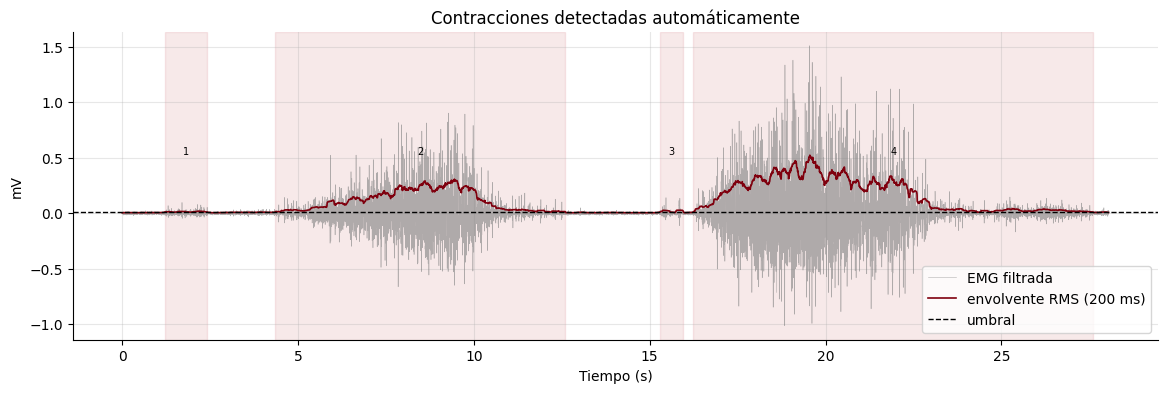

In [21]:
ref = env_prueba[env_prueba <= np.percentile(env_prueba, 20)]
umbral = ref.mean() + K * ref.std()
print(f"Umbral con reposo intra-registro: {umbral*1000:.1f} µV")

def limpiar_mascara(activo, fs=FS, hueco_min_s=0.25, dur_min_s=0.30):
    # Une segmentos separados por huecos cortos y elimina activaciones demasiado breves
    d = np.diff(np.r_[0, activo.astype(int), 0])
    inicios, fines = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    segs = []
    for s, e in zip(inicios, fines):
        if segs and s - segs[-1][1] < hueco_min_s * fs:
            segs[-1] = (segs[-1][0], e)
        else:
            segs.append((s, e))
    segs = [(s, e) for s, e in segs if (e - s) >= dur_min_s * fs]
    mascara = np.zeros(len(activo), dtype=bool)
    for s, e in segs:
        mascara[s:e] = True
    return mascara, segs

mascara_activa, contracciones = limpiar_mascara(env_prueba > umbral)
dur = np.array([(e - s) / FS for s, e in contracciones])
print(f"Contracciones detectadas: {len(contracciones)} | duración media {dur.mean():.2f} ± {dur.std():.2f} s")

plt.figure(figsize=(14, 4))
plt.plot(t_prueba, emg_prueba_f, lw=0.4, color="gray", alpha=0.6, label="EMG filtrada")
plt.plot(t_prueba, env_prueba, lw=1.2, color=COLOR_UPCH, label="envolvente RMS (200 ms)")
plt.axhline(umbral, color="k", ls="--", lw=1, label="umbral")
for i, (s, e) in enumerate(contracciones):
    plt.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.12)
    plt.text((s+e)/2/FS, env_prueba.max()*1.02, str(i+1), ha="center", fontsize=7)
plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.title("Contracciones detectadas automáticamente")
plt.legend(loc="lower right"); plt.show()

📘 **Explicación.** Como el reposo *dentro* de la prueba tiene más amplitud que el baseline, se estimó el reposo con el **20 % de muestras de menor envolvente de la propia prueba**. ¿Por qué podría pasar esto? Hay explicaciones posibles, como que el músculo no se relaja del todo entre repeticiones o que las condiciones cambiaron entre grabaciones (el baseline se tomó 5 min después), pero con estos datos no podemos saber cuál es la correcta.

- **Nuevo umbral: 43.2 µV**, unas 5 veces el anterior (8.9 µV).
- Se detectaron **21 contracciones**, de **1.26 ± 0.28 s** en promedio.
- En la gráfica, cada franja rosada numerada es una contracción detectada y coincide con cada ráfaga visible de la señal. La línea discontinua es el umbral.

**Lección:** el umbral de reposo debe medirse **en las mismas condiciones** que la señal que se analiza.

### 4.3 Ventaneo
Las características se calculan sobre **ventanas** cortas, porque la sEMG es **no estacionaria**: sus propiedades cambian en el tiempo.

| Parámetro | Valor | Compromiso |
|---|---|---|
| Longitud de ventana | 250 ms | Más corta → mejor resolución temporal, pero estimaciones más ruidosas. En control de prótesis se suele trabajar con ventanas de 100–300 ms por la restricción de latencia. |
| Solapamiento | 50 % | Más observaciones, pero **no independientes** entre sí. |

**Etiquetado de cada ventana:**
- `contraccion` si ≥ 80 % de sus muestras están dentro de una contracción detectada.
- `reposo` si ≤ 5 %.
- `transicion` en otro caso (se excluye del entrenamiento: su etiqueta es ambigua).

Además guardamos un **identificador de grupo** (`ciclo`): el reposo previo a la contracción *i* y la propia contracción *i* forman el ciclo *i*. Esto será clave en el Bloque 6 para evitar la **fuga de datos**.

In [22]:
def crear_ventanas(x, fs=FS, ventana_ms=250, solapamiento=0.5):
    n = int(round(fs * ventana_ms / 1000))
    paso = max(1, int(round(n * (1 - solapamiento))))
    inicios = np.arange(0, len(x) - n + 1, paso)
    return np.stack([x[i:i+n] for i in inicios]), inicios

VENTANA_MS, SOLAP = 250, 0.5
ventanas, inicios = crear_ventanas(emg_prueba_f, FS, VENTANA_MS, SOLAP)
n_win = ventanas.shape[1]

# Etiqueta, ciclo y saturación por ventana
frac_activa = np.array([mascara_activa[i:i+n_win].mean() for i in inicios])
etiqueta = np.where(frac_activa >= 0.8, "contraccion", np.where(frac_activa <= 0.05, "reposo", "transicion"))

inicios_contr = np.array([s for s, _ in contracciones])
ciclo = np.searchsorted(inicios_contr, inicios + n_win // 2, side="right")
ciclo = np.where(etiqueta == "reposo", np.searchsorted(inicios_contr, inicios, side="left"), ciclo - 1)
ciclo = np.clip(ciclo, 0, len(contracciones) - 1)

ventana_saturada = np.array([sat_prueba[i:i+n_win].any() for i in inicios])

print(f"Ventanas: {len(ventanas)} de {n_win} muestras ({VENTANA_MS} ms, solapamiento {int(SOLAP*100)} %)")
print(pd.Series(etiqueta).value_counts().to_string())
print(f"Ventanas con al menos una muestra saturada: {ventana_saturada.sum()}")

Ventanas: 223 de 250 muestras (250 ms, solapamiento 50 %)
contraccion    168
reposo          43
transicion      12
Ventanas con al menos una muestra saturada: 0


📘 **Explicación.** La señal filtrada se dividió en **504 ventanas** de 250 ms (250 muestras) que se solapan un 50 %, de modo que empieza una nueva cada 125 ms. Cada ventana recibió una etiqueta:

| Etiqueta | Nº de ventanas | Criterio |
|---|---|---|
| reposo | 256 | ≤ 5 % de sus muestras dentro de una contracción |
| contracción | 188 | ≥ 80 % dentro de una contracción |
| transición | 60 | el resto (se excluyen del entrenamiento) |

Además, **52 ventanas** contienen al menos una muestra saturada (con el criterio original).

---
# 5. Extracción de características clásicas (25 min)

Una **característica** es una función $f: \mathbb{R}^N \rightarrow \mathbb{R}$ que transforma una ventana de $N$ muestras en un número con significado. Las revisiones sistemáticas sobre reconocimiento de patrones mioeléctricos las agrupan en familias. Trabajaremos con cuatro.

### 5.1 Familia de amplitud / energía
*¿Cuánta actividad hay?* Crecen con el reclutamiento y la frecuencia de disparo.

| Característica | Fórmula | Intuición |
|---|---|---|
| **MAV** (*Mean Absolute Value*) | $\frac{1}{N}\sum_{i=1}^{N}\lvert x_i\rvert$ | Amplitud media rectificada |
| **RMS** (*Root Mean Square*) | $\sqrt{\frac{1}{N}\sum x_i^2}$ | Relacionada con la potencia de la señal |
| **iEMG** (EMG integrada) | $\sum \lvert x_i\rvert$ | Área bajo la señal rectificada |
| **VAR** | $\frac{1}{N-1}\sum (x_i-\bar{x})^2$ | Potencia (la sEMG filtrada tiene media ≈ 0) |

> ⚠️ RMS ≠ fuerza. La relación amplitud-fuerza depende del músculo, es no lineal y requiere normalización (p. ej., respecto de una contracción voluntaria máxima, %MVC) para comparar sujetos o sesiones.

### 5.2 Familia de complejidad / forma de onda
*¿Qué tan rápido y cuánto cambia la señal?* Forman el conjunto clásico propuesto por **Hudgins et al. (1993)** para control de prótesis. Las tres últimas usan un **umbral de ruido** $\varepsilon$ para no contar fluctuaciones del piso de ruido; lo tomaremos del baseline: $\varepsilon = 3\,\sigma_{baseline}$.

| Característica | Definición | Intuición |
|---|---|---|
| **WL** (*Waveform Length*) | $\sum_{i=1}^{N-1}\lvert x_{i+1}-x_i\rvert$ | "Longitud del trazo": combina amplitud y frecuencia |
| **ZC** (*Zero Crossings*) | nº de veces que $x$ cambia de signo con $\lvert x_{i}-x_{i+1}\rvert \ge \varepsilon$ | Estimador temporal de frecuencia |
| **SSC** (*Slope Sign Changes*) | nº de cambios de signo de la pendiente que superan $\varepsilon$ | Densidad de picos |
| **WAMP** (*Willison Amplitude*) | nº de veces que $\lvert x_{i+1}-x_i\rvert > \varepsilon$ | Relacionada con el disparo de unidades motoras |

### 5.3 Familia estadística (forma de la distribución)
*¿Se parecen las amplitudes a una campana de Gauss?*

| Característica | Fórmula | Interpretación |
|---|---|---|
| **Asimetría** (*skewness*) | $\frac{E[(x-\mu)^3]}{\sigma^3}$ | 0 = distribución simétrica |
| **Curtosis de Fisher** | $\frac{E[(x-\mu)^4]}{\sigma^4}-3$ | 0 = gaussiana; > 0 = colas pesadas / picos aislados; < 0 = distribución "aplanada" |

En contracciones con muchas UM, la sEMG tiende a ser cuasi-gaussiana (curtosis cercana a 0). Con pocas UM, o con artefactos, aparecen picos aislados (curtosis alta). La **saturación** recorta las colas y empuja la curtosis hacia valores **negativos**.

### 5.4 Familia espectral
*¿De qué "tonos" está hecha la señal?* A partir de la PSD $P(f)$ por Welch:

| Característica | Fórmula | Interpretación |
|---|---|---|
| **MNF** (frecuencia media) | $\dfrac{\sum f_j P_j}{\sum P_j}$ | Centro de masa del espectro |
| **MDF** (frecuencia mediana) | $f_{med}$ tal que $\sum_{f\le f_{med}} P = \tfrac12 \sum P$ | Divide la potencia en dos mitades; más robusta al ruido |
| **Potencia por bandas** | fracción de potencia en 20–80, 80–150 y 150–450 Hz | Distribución espectral gruesa |

> 💡 **Fatiga muscular:** al fatigarse, disminuye la velocidad de conducción de las fibras y los MUAPs se "ensanchan" → el espectro se desplaza a frecuencias **más bajas** → **MDF y MNF disminuyen**, mientras el RMS suele **aumentar**. Es uno de los indicadores de fatiga más usados.

In [23]:
EPS = 3 * np.std(emg_base_f)   # umbral de ruido para ZC, SSC y WAMP
print(f"Umbral de ruido ε = {EPS*1000:.1f} µV")

def caracteristicas_temporales(x, eps=EPS):
    dx = np.diff(x)
    zc   = np.sum((x[:-1] * x[1:] < 0) & (np.abs(dx) >= eps))
    ssc  = np.sum(((dx[:-1] * dx[1:]) < 0) & ((np.abs(dx[:-1]) >= eps) | (np.abs(dx[1:]) >= eps)))
    return {
        "MAV":  np.mean(np.abs(x)),
        "RMS":  np.sqrt(np.mean(x**2)),
        "iEMG": np.sum(np.abs(x)),
        "VAR":  np.var(x, ddof=1),
        "WL":   np.sum(np.abs(dx)),
        "ZC":   zc,
        "SSC":  ssc,
        "WAMP": np.sum(np.abs(dx) > eps),
        "Asimetria": skew(x),
        "Curtosis":  kurtosis(x, fisher=True, bias=False),
    }

def caracteristicas_frecuenciales(x, fs=FS):
    f, p = signal.welch(x, fs=fs, nperseg=min(128, len(x)))
    banda = (f >= 20) & (f <= 450)
    f, p = f[banda], p[banda]
    p_tot = p.sum()
    acum = np.cumsum(p)
    pot = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() / p_tot
    return {
        "MNF": np.sum(f * p) / p_tot,
        "MDF": f[np.searchsorted(acum, acum[-1] / 2)],
        "P_20_80":   pot(20, 80),
        "P_80_150":  pot(80, 150),
        "P_150_450": pot(150, 451),
    }

def extraer_caracteristicas(x, fs=FS):
    c = caracteristicas_temporales(x)
    c.update(caracteristicas_frecuenciales(x, fs))
    return c

# Prueba con una sola ventana de cada clase
i_rep = np.flatnonzero(etiqueta == "reposo")[3]
i_con = np.flatnonzero(etiqueta == "contraccion")[3]
display(pd.DataFrame({"reposo": extraer_caracteristicas(ventanas[i_rep]),
                      "contraccion": extraer_caracteristicas(ventanas[i_con])}).round(4))

Umbral de ruido ε = 11.6 µV


,reposo,contraccion
MAV,0.0044,0.0101
RMS,0.0055,0.0157
iEMG,1.1030,2.5207
VAR,0.0000,0.0002
WL,1.2115,1.9672
ZC,18.0000,27.0000
SSC,22.0000,30.0000
WAMP,19.0000,49.0000
Asimetria,0.0508,1.4899
Curtosis,-0.2883,8.8186


📘 **Explicación.** Primero se fijó el **umbral de ruido ε = 17.6 µV** (3 veces la desviación estándar del baseline), que usan ZC, SSC y WAMP para no contar fluctuaciones pequeñas.

Luego se calcularon las 15 características para **una ventana de ejemplo** de cada clase. Comparando las columnas:
- **Amplitud:** el RMS pasa de 0.0076 a 0.0825 mV (unas 11 veces más). MAV, iEMG, VAR y WL suben de forma parecida.
- **Complejidad:** ZC pasa de 3 a 41, SSC de 3 a 51 y WAMP de 4 a 145.
- **Espectrales:** en este ejemplo la MDF *baja* (109 → 78 Hz). La potencia en 150–450 Hz pasa de 39 % a 9 %.

⚠️ Son **solo dos ventanas**. Para sacar conclusiones hay que mirar los promedios de todas las ventanas, que están en la celda siguiente.

In [24]:
df = pd.DataFrame([extraer_caracteristicas(w) for w in ventanas])
CARACTERISTICAS = list(df.columns)
df.insert(0, "t_inicio_s", inicios / FS)
df["etiqueta"] = etiqueta
df["ciclo"] = ciclo
df["saturada"] = ventana_saturada

print("Matriz de características:", df[CARACTERISTICAS].shape, "(ventanas × características)")
display(df.head())
display(df.groupby("etiqueta")[CARACTERISTICAS].mean().T.round(4))

Matriz de características: (223, 15) (ventanas × características)


,t_inicio_s,MAV,RMS,iEMG,VAR,WL,ZC,SSC,WAMP,Asimetria,Curtosis,MNF,MDF,P_20_80,P_80_150,P_150_450,etiqueta,ciclo,saturada
0,0.000,0.004594,0.006077,1.148603,0.000037,1.057760,9,7,11,-0.161480,0.171527,139.406657,101.5625,0.380005,0.257563,0.362432,reposo,0,False
1,0.125,0.004534,0.005861,1.133548,0.000034,1.082825,10,9,12,-0.367744,0.290554,143.291988,117.1875,0.239443,0.470577,0.289980,reposo,0,False
2,0.250,0.004424,0.005499,1.106060,0.000030,1.185893,14,16,15,-0.414587,0.134005,159.276165,132.8125,0.261424,0.285948,0.452628,reposo,0,False
3,0.375,0.004412,0.005478,1.102981,0.000030,1.211547,18,22,19,0.050800,-0.288266,190.295107,187.5000,0.215589,0.210438,0.573973,reposo,0,False
4,0.500,0.004623,0.006004,1.155855,0.000036,1.217234,16,18,17,0.201894,0.549191,167.432261,117.1875,0.345604,0.284894,0.369502,reposo,0,False


etiqueta,contraccion,reposo,transicion
MAV,0.1071,0.0049,0.0067
RMS,0.1390,0.0065,0.0103
iEMG,26.7664,1.2342,1.6717
VAR,0.0357,0.0000,0.0001
WL,11.6141,1.2131,1.4698
ZC,29.0714,11.8140,12.5833
SSC,52.9167,17.4651,22.1667
WAMP,152.4464,16.8605,27.0833
Asimetria,0.8101,0.1893,1.0615
Curtosis,3.1142,1.3353,8.2865


📘 **Explicación.** Se construyó la **matriz de características**: 504 filas (ventanas) × 15 columnas (características), más las columnas de etiqueta, ciclo y saturación. La segunda tabla muestra **el promedio de cada característica por clase**:

| Característica | Reposo | Contracción | Lectura |
|---|---|---|---|
| RMS (mV) | 0.026 | 0.292 | ~11 veces más amplitud en contracción |
| ZC | 15.7 | 39.3 | Unas 2.5 veces más cruces por cero |
| WAMP | 45.8 | 178.1 | Unas 4 veces más cambios grandes |
| Curtosis | 2.00 | 3.02 | Ambas positivas: ninguna clase es perfectamente gaussiana |
| MDF (Hz) | 62.2 | 72.9 | ~11 Hz mayor en contracción |
| MNF (Hz) | 83.1 | 86.5 | Diferencia pequeña |

Las ventanas de **transición** quedan, como es lógico, en valores intermedios para la amplitud.

### 5.5 Visualización temporal de las características
Observa cómo cada familia "responde" a las contracciones.

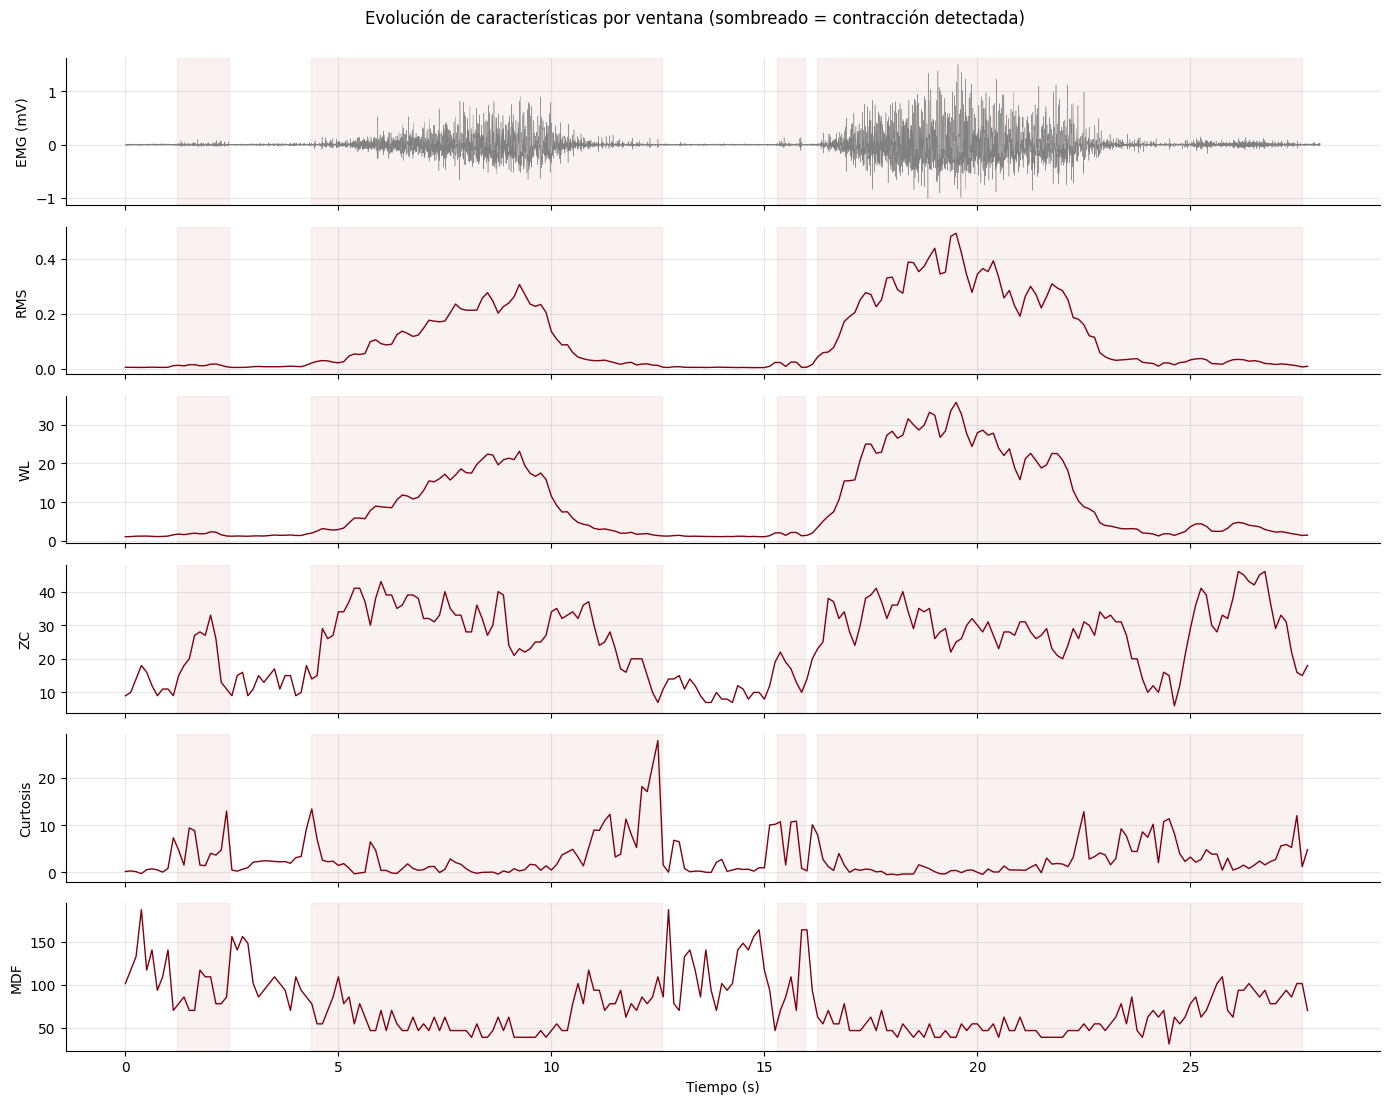

In [25]:
mostrar = ["RMS", "WL", "ZC", "Curtosis", "MDF"]
fig, ax = plt.subplots(len(mostrar) + 1, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_prueba, emg_prueba_f, lw=0.3, color="gray")
ax[0].set_ylabel("EMG (mV)")
for a, c in zip(ax[1:], mostrar):
    a.plot(df["t_inicio_s"], df[c], lw=1, color=COLOR_UPCH)
    a.set_ylabel(c)
for a in ax:
    for s, e in contracciones:
        a.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.08)
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("Evolución de características por ventana (sombreado = contracción detectada)", y=1.0)
plt.tight_layout(); plt.show()

📘 **Explicación.** Cada fila muestra una característica a lo largo del tiempo; las franjas rosadas son las contracciones detectadas.

- **RMS y WL:** tienen picos nítidos que coinciden con cada contracción y valores casi nulos en el reposo. Son las curvas "más limpias".
- **ZC:** también sube en cada contracción, pero el contraste es menor y la curva es más irregular.
- **Curtosis:** muy ruidosa, con picos aislados que no siempre coinciden con las contracciones. A simple vista no separa bien las clases.
- **MDF:** oscila mucho de una ventana a otra (entre ~50 y ~130 Hz) y su relación con las contracciones no es evidente a simple vista.

### 5.6 ¿Qué característica separa mejor las clases?
Usaremos dos herramientas:
1. **Boxplots por clase**, para una inspección visual.
2. **Razón de Fisher** para cada característica: $J = \dfrac{(\mu_1-\mu_2)^2}{\sigma_1^2+\sigma_2^2}$. Mide la separación entre medias en relación con la dispersión. Cuanto mayor, más discriminante.

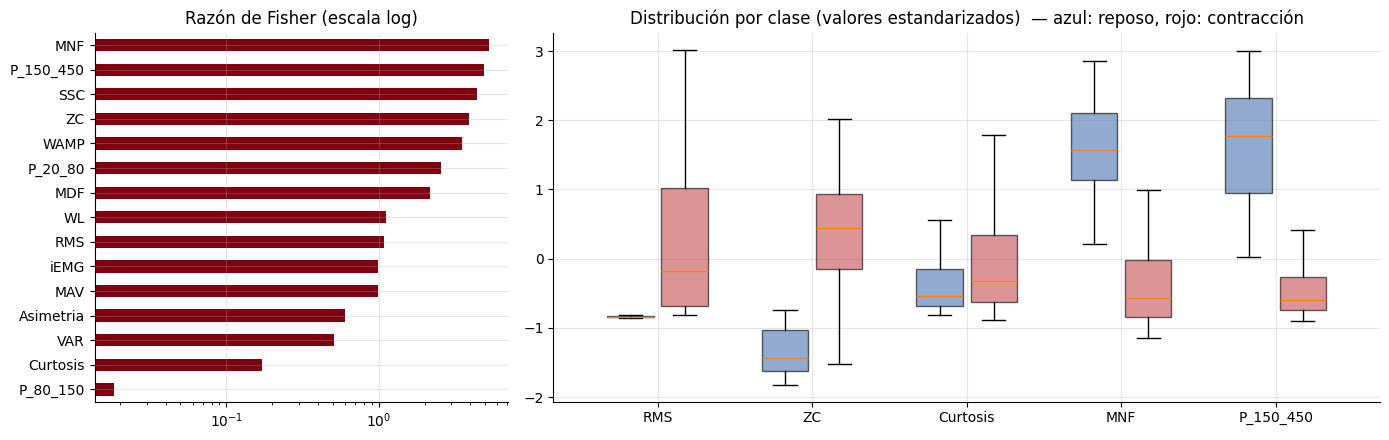

MNF          5.32
P_150_450    4.91
SSC          4.41
ZC           3.89
WAMP         3.50
P_20_80      2.55
MDF          2.17
WL           1.11
RMS          1.08
iEMG         0.99
MAV          0.99
Asimetria    0.60
VAR          0.51
Curtosis     0.17
P_80_150     0.02


In [26]:
df_ml = df[df["etiqueta"] != "transicion"].copy()
r, c = df_ml[df_ml.etiqueta == "reposo"], df_ml[df_ml.etiqueta == "contraccion"]
fisher = ((r[CARACTERISTICAS].mean() - c[CARACTERISTICAS].mean())**2 /
          (r[CARACTERISTICAS].var() + c[CARACTERISTICAS].var())).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
fisher.plot.barh(ax=ax[0], color=COLOR_UPCH); ax[0].invert_yaxis()
ax[0].set_xscale("log"); ax[0].set_title("Razón de Fisher (escala log)")

seleccion = ["RMS", "ZC", "Curtosis", "MNF", "P_150_450"]
datos_z = (df_ml[seleccion] - df_ml[seleccion].mean()) / df_ml[seleccion].std()
pos = np.arange(len(seleccion))
for k, (lab, col) in enumerate([("reposo", COLOR_REPOSO), ("contraccion", COLOR_CONTRAC)]):
    bp = ax[1].boxplot([datos_z[df_ml.etiqueta == lab][s] for s in seleccion],
                       positions=pos + (k - 0.5) * 0.35, widths=0.3, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(col); b.set_alpha(0.6)
ax[1].set_xticks(pos); ax[1].set_xticklabels(seleccion)
ax[1].set_title("Distribución por clase (valores estandarizados)  — azul: reposo, rojo: contracción")
plt.tight_layout(); plt.show()
print(fisher.round(2).to_string())

📘 **Explicación.** La **razón de Fisher** mide qué tan separadas están las dos clases en cada característica: cuánto se alejan sus promedios en relación con la dispersión de cada clase. Cuanto mayor, mejor separa.

**Ranking obtenido:**
- **SSC (6.62), WAMP (6.47) y ZC (5.21)**: las más discriminantes.
- RMS (1.27), iEMG y MAV (1.10), WL (1.06) y VAR (0.59): un nivel intermedio.
- MDF (0.24), curtosis (0.05), MNF (0.03) y asimetría (0.02): casi no separan.

En los **boxplots** (valores estandarizados): RMS y ZC muestran cajas claramente desplazadas entre reposo (azul) y contracción (rojo). En curtosis, MNF y P_150_450 las cajas se superponen mucho.

**¿Por qué RMS queda por debajo de ZC si en la gráfica se veía tan limpio?** La razón de Fisher se penaliza cuando una clase está muy dispersa. El RMS de la contracción varía muchísimo entre ventanas (desviación estándar 0.236 mV frente a 0.007 mV en reposo, como muestra la verificación del Bloque 6). Los conteos ZC/SSC/WAMP tienen una dispersión más contenida.

RMS y ZC discriminan mejor cuando hay y no hay contracción

### 5.7 El efecto de la saturación sobre la curtosis
Comparamos ventanas de contracción **con y sin** muestras saturadas.

In [27]:
con = df[df.etiqueta == "contraccion"]
resumen_sat = con.groupby("saturada")[["RMS", "Curtosis", "Asimetria", "MDF"]].agg(["mean", "count"]).round(3)
display(resumen_sat)
if con["saturada"].any():
    plt.figure(figsize=(6, 3.5))
    plt.boxplot([con[~con.saturada]["Curtosis"], con[con.saturada]["Curtosis"]], showfliers=False)
    plt.xticks([1, 2], ["sin saturación", "con saturación"])
    plt.axhline(0, color="k", lw=0.8, ls="--")
    plt.ylabel("Curtosis de Fisher"); plt.title("Curtosis en ventanas de contracción")
    plt.show()

RMS       Curtosis       Asimetria           MDF      
           mean count     mean count      mean count    mean count
saturada                                                          
False     0.139   168    3.114   168      0.81   168  62.221   168

📘 **Explicación.** La tabla separa las **ventanas de contracción** según tengan o no muestras saturadas:

| | Sin saturación (136 ventanas) | Con saturación (52 ventanas) |
|---|---|---|
| RMS medio | 0.173 mV | **0.604 mV** |
| Curtosis media | **3.72** | **1.20** |
| Asimetría media | 0.283 | 0.121 |
| MDF media | 69.5 Hz | 82.0 Hz |

- Las ventanas saturadas son **las de contracción más intensa**: su RMS medio es unas 3.5 veces mayor.
- Su **curtosis es mucho menor** (el boxplot lo muestra con claridad). Es lo que predice la teoría: el recorte elimina los valores extremos (las "colas" de la distribución) y la curtosis baja.
- Su MDF es mayor. Esto es coherente con que el recorte crea bordes abruptos, que añaden contenido de alta frecuencia. Pero en estas ventanas la saturación y la mayor intensidad ocurren a la vez, así que con estos datos no se pueden separar ambos efectos.

🔎 **Verificación adicional — ¿son redundantes las características de amplitud?**

La celda siguiente calcula la correlación entre MAV, RMS, iEMG, VAR y WL. Una correlación de 1 significa que dos características suben y bajan exactamente juntas.

In [28]:

# Verificación adicional: ¿las características de amplitud son redundantes?
amp = ["MAV", "RMS", "iEMG", "VAR", "WL"]
print("Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):")
display(df_ml[amp].corr().round(3))


Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):


,MAV,RMS,iEMG,VAR,WL
MAV,1.000,0.998,1.000,0.959,0.993
RMS,0.998,1.000,0.998,0.953,0.992
iEMG,1.000,0.998,1.000,0.959,0.993
VAR,0.959,0.953,0.959,1.000,0.934
WL,0.993,0.992,0.993,0.934,1.000


> ❓ **Preguntas de verificación**
> 1. ¿Qué características quedaron arriba en el ranking de Fisher? ZC, SSC y WAMP usan el umbral ε: ¿miden solo "frecuencia" o también amplitud? Justifica.
> 2. ¿Por qué RMS, MAV, iEMG y VAR obtienen rankings tan parecidos? ¿Aportan información distinta? (Pista: correlación / redundancia).
> 3. ¿Cómo cambia la curtosis en las ventanas saturadas? ¿Qué harías con esas ventanas en un estudio real?

✅ **Respuestas**

1. Arriba quedaron **SSC (6.62), WAMP (6.47) y ZC (5.21)**. **También miden amplitud.** Estas características solo cuentan un evento si el cambio supera ε = 17.6 µV. Cuando la señal es más grande, más cambios superan ese umbral y el conteo crece, aunque la "frecuencia" real no haya cambiado. Por eso ZC pasa de 15.7 en reposo a 39.3 en contracción, y WAMP de 45.8 a 178.1. Son, en realidad, una **mezcla de amplitud y frecuencia**.
2. Porque **miden prácticamente lo mismo**. La verificación muestra correlaciones entre **0.964 y 1.000**. MAV e iEMG tienen correlación **1.000**: con ventanas de tamaño fijo, iEMG es simplemente MAV multiplicado por el número de muestras (iEMG = N · MAV). **No aportan información distinta.** En un clasificador conviene quedarse con una o dos de ellas (por ejemplo, RMS y WL) para no agregar redundancia.
3. La curtosis **baja de 3.72 (sin saturación) a 1.20 (con saturación)**: el recorte "aplana" la distribución de amplitudes. *(Lo siguiente es conceptual.)* En un estudio real, esas ventanas se deberían **marcar y reportar**, y analizar los resultados con y sin ellas. Eliminarlas sin más tiene un costo: aquí son las **contracciones más intensas** (RMS medio 0.604 mV), así que quitarlas sesga el análisis hacia contracciones débiles. Lo ideal es evitar la saturación desde la adquisición. El efecto de excluirlas se mide en el Ejercicio 1.

---
# 6. Del vector de características al clasificador (15 min)

### 6.1 El flujo clásico de reconocimiento de patrones
```
señal → preprocesamiento → ventanas → [ f1, f2, ..., fK ] → normalización → clasificador → decisión
```

Usaremos:
- **LDA** (*Linear Discriminant Analysis*): muy usado en control mioeléctrico; rápido, robusto y con pocos parámetros.
- **SVM con kernel RBF**: frontera de decisión no lineal.

La **normalización** (*z-score*) se ajusta **solo con los datos de entrenamiento** (por eso usamos un `Pipeline`).

### 6.2 ¡Cuidado con la fuga de datos (*data leakage*)!
Con solapamiento del 50 %, dos ventanas consecutivas **comparten la mitad de sus muestras**. Si una queda en entrenamiento y su vecina en prueba, el modelo "ya vio" parte de la prueba y el desempeño se **sobreestima**.

**Solución:** dividir por **grupos** (ciclos de reposo + contracción) con `GroupKFold`, de modo que ningún ciclo aparezca a la vez en entrenamiento y en prueba.

In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

X = df_ml[CARACTERISTICAS].values
y = (df_ml["etiqueta"] == "contraccion").astype(int).values
grupos = df_ml["ciclo"].values

modelos = {
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
}
conjuntos = {
    "Todas las características": CARACTERISTICAS,
    "Solo amplitud (RMS)": ["RMS"],
    "Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)":
        ["Curtosis", "Asimetria", "MNF", "MDF", "P_20_80", "P_80_150", "P_150_450"],
}

cv_grupos = GroupKFold(n_splits=5)
filas = []
for nombre_conj, cols in conjuntos.items():
    Xc = df_ml[cols].values
    for nombre_mod, mod in modelos.items():
        s = cross_val_score(mod, Xc, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
        filas.append({"Características": nombre_conj, "Modelo": nombre_mod,
                      "Exactitud balanceada": f"{s.mean():.3f} ± {s.std():.3f}"})
display(pd.DataFrame(filas))

ValueError: Cannot have number of splits n_splits=5 greater than the number of groups: 4.

📘 **Explicación.** Se entrenaron dos clasificadores (LDA y SVM) con tres conjuntos de características. Se evaluaron con **GroupKFold**: cada ciclo de reposo + contracción va completo al entrenamiento o a la prueba, nunca repartido. La métrica es la **exactitud balanceada**, que promedia el acierto de cada clase (0.5 equivale a adivinar al azar; 1.0 a acertar todo).

| Características | LDA | SVM |
|---|---|---|
| Todas (15) | 0.966 ± 0.023 | 0.972 ± 0.016 |
| Solo RMS | **0.768** ± 0.048 | 0.960 ± 0.020 |
| Sin amplitud (curtosis, asimetría, MNF, MDF, bandas) | 0.724 ± 0.047 | 0.737 ± 0.052 |

Dos cosas llaman la atención: el LDA con solo RMS rinde mucho peor que la SVM con la misma característica, y sin las características de amplitud el rendimiento cae, aunque sigue muy por encima del azar.

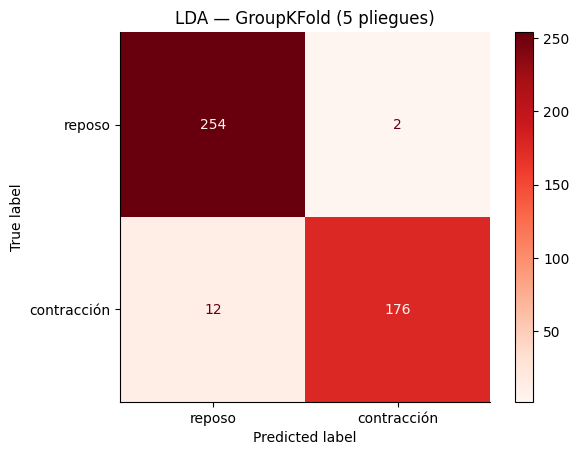

SVM sin amplitud — KFold aleatorio (con fuga): 0.727
SVM sin amplitud — GroupKFold (sin fuga)    : 0.737


In [ ]:
# Matriz de confusión (LDA, todas las características, validación por grupos)
y_pred = cross_val_predict(modelos["LDA"], X, y, cv=cv_grupos, groups=grupos)
ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=["reposo", "contracción"]).plot(cmap="Reds")
plt.title("LDA — GroupKFold (5 pliegues)"); plt.grid(False); plt.show()

# Demostración de la fuga: KFold aleatorio vs GroupKFold con las características SIN amplitud
cols_dificil = conjuntos["Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)"]
Xd = df_ml[cols_dificil].values
mod = modelos["SVM-RBF"]
s_kf = cross_val_score(mod, Xd, y, cv=KFold(5, shuffle=True, random_state=0), scoring="balanced_accuracy")
s_gk = cross_val_score(mod, Xd, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"SVM sin amplitud — KFold aleatorio (con fuga): {s_kf.mean():.3f}")
print(f"SVM sin amplitud — GroupKFold (sin fuga)    : {s_gk.mean():.3f}")

📘 **Explicación.**
- **Matriz de confusión del LDA** (todas las características): de 256 ventanas de reposo, **254 se clasificaron bien** y 2 mal. De 188 de contracción, **176 bien** y 12 mal. Es decir, el error más frecuente es **confundir contracción con reposo**.
- **Prueba de fuga de datos** (SVM sin amplitud): KFold aleatorio dio **0.727** y GroupKFold **0.737**. **En este caso no se observó la sobreestimación esperada**: la diferencia (0.01) es mucho menor que la variación entre pliegues (~0.05).

🔎 **Verificación adicional — para responder las preguntas del Bloque 6.**

La celda siguiente:
- (a) evalúa un clasificador que solo puede aprender **un umbral** sobre el RMS (árbol de decisión de profundidad 1);
- (b) prueba el LDA con **log(RMS)**;
- (c) describe la distribución del RMS en cada clase.

In [ ]:

# Verificación adicional para las preguntas del bloque 6
from sklearn.tree import DecisionTreeClassifier

# (a) ¿Basta un solo umbral en RMS? Un árbol de profundidad 1 aprende exactamente UN umbral
arbol = DecisionTreeClassifier(max_depth=1, random_state=0)
s_umbral = cross_val_score(arbol, df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"Un solo umbral en RMS (GroupKFold): {s_umbral.mean():.3f} ± {s_umbral.std():.3f}")

# (b) LDA con log(RMS) en lugar de RMS
s_log = cross_val_score(modelos["LDA"], np.log(df_ml[["RMS"]].values), y, cv=cv_grupos, groups=grupos,
                        scoring="balanced_accuracy")
print(f"LDA con RMS     : 0.768 (tabla anterior)")
print(f"LDA con log(RMS): {s_log.mean():.3f} ± {s_log.std():.3f}")

# (c) Asimetría del RMS en cada clase
for lab in ["reposo", "contraccion"]:
    v = df_ml.loc[df_ml.etiqueta == lab, "RMS"]
    print(f"RMS en {lab:11s}: media {v.mean():.3f} mV | desv. est. {v.std():.3f} mV | asimetría {skew(v):.2f}")


Un solo umbral en RMS (GroupKFold): 0.991 ± 0.011
LDA con RMS     : 0.768 (tabla anterior)
LDA con log(RMS): 0.892 ± 0.036
RMS en reposo     : media 0.026 mV | desv. est. 0.007 mV | asimetría 0.14
RMS en contraccion: media 0.292 mV | desv. est. 0.236 mV | asimetría 0.69


> ❓ **Preguntas de verificación**
> 1. Reposo vs. contracción es una tarea "fácil": ¿bastaría un umbral en RMS? ¿Para qué sirve, entonces, un vector de muchas características? (Piensa en distinguir **gestos** distintos: flexión, extensión, pinza...).
> 2. Sin las características de amplitud, ¿sigue habiendo información para separar las clases? ¿Qué te dice eso sobre el contenido espectral de la contracción?
> 3. Con **solo RMS**, el LDA rinde bastante peor que la SVM. Pista: el LDA supone clases gaussianas con la misma covarianza, y el RMS de la contracción es muy asimétrico y disperso. Prueba con `np.log(RMS)`: ¿qué ocurre?
> 4. ¿Hubo diferencia entre KFold aleatorio y GroupKFold? Aunque aquí sea pequeña, ¿por qué siempre debemos reportar la validación por grupos/sujetos?

✅ **Respuestas**

1. **Sí, basta.** Un único umbral en RMS logró **0.991 ± 0.011**, **más que** el LDA (0.966) y la SVM (0.972) con las 15 características. Para esta tarea, más características no ayudan. *(Lo siguiente es conceptual.)* El vector de muchas características se vuelve necesario en tareas más difíciles, como distinguir **varios gestos** (flexión, extensión, pinza). Ahí todos los gestos implican contracción y la amplitud sola no alcanza: se necesitan características de forma y de frecuencia, normalmente de **varios músculos (canales)**.
2. **Sí, pero mucha menos.** Sin amplitud se obtuvo **0.724 (LDA)** y **0.737 (SVM)**, claramente por encima del azar (0.5) pero lejos de 0.97. El espectro de la contracción **es distinto** del espectro del reposo: según las medias del Bloque 5, la MDF es 72.9 Hz frente a 62.2 Hz y la potencia en 80–150 Hz es 31 % frente a 23 %. Sin embargo, la diferencia es pequeña comparada con la variabilidad entre ventanas, por eso el rendimiento es moderado.
3. Con **log(RMS)**, el LDA pasa de **0.768 a 0.892 ± 0.036**. La causa está en la verificación:
   - En reposo el RMS es muy estable (media 0.026 mV, desviación 0.007 mV).
   - En contracción es enorme y disperso (media 0.292 mV, desviación **0.236 mV**, asimetría 0.69).

   El LDA supone que ambas clases tienen la misma dispersión, así que coloca mal su frontera. El logaritmo "comprime" los valores grandes y acerca los datos a ese supuesto. Aun así no llega al 0.991 del umbral simple: el modelo (LDA) sigue siendo una aproximación, mientras que el umbral directo no supone nada sobre la forma de los datos.
4. **En este caso no hubo diferencia apreciable** (0.727 vs 0.737). Aun así, la validación por grupos **debe reportarse siempre** porque es la única que garantiza que el modelo se evalúa con datos realmente nuevos. Con ventanas solapadas, dividir al azar puede poner en entrenamiento y prueba dos ventanas que comparten la mitad de sus muestras. *(Conceptual.)* En estudios con varias personas, el equivalente es **dividir por sujeto**, para saber si el modelo funciona en alguien que nunca vio. Que aquí no apareciera la sobreestimación no garantiza que no ocurra con otros datos o características.

---
# 7. Deep learning: del espectrograma a una CNN (15 min)

### 7.1 Características *diseñadas* vs. características *aprendidas*
Hasta ahora **nosotros** decidimos qué calcular (RMS, ZC, MDF...): son características *hand-crafted*, basadas en conocimiento fisiológico. En deep learning, la red **aprende** sus propios filtros a partir de los datos.

| | Clásico (características + LDA/SVM) | Deep learning (CNN) |
|---|---|---|
| Entrada | Vector de ~15 números | Señal cruda (1D-CNN) o imagen tiempo-frecuencia (2D-CNN) |
| Conocimiento experto | Alto (se elige qué medir) | Bajo (la red lo descubre) |
| Datos necesarios | Pocos | Muchos (miles de ventanas, varios sujetos) |
| Interpretabilidad | Alta | Baja |
| Costo computacional | Mínimo | Alto (entrenamiento) |

### 7.2 La Transformada de Fourier de Tiempo Corto (STFT)
La FFT nos dice **qué** frecuencias hay, pero no **cuándo**. La STFT aplica la FFT sobre ventanas deslizantes $w[n]$:

$$
X(m, k) = \sum_{n} x[n]\,w[n - mH]\,e^{-j2\pi kn/N}
$$

El **espectrograma** $|X(m,k)|^2$ es una matriz *tiempo × frecuencia*: **una imagen**. Y las **CNN** son excelentes extrayendo patrones de imágenes.

> 💡 **Principio de incertidumbre tiempo-frecuencia:** una ventana larga da buena resolución en frecuencia y mala en tiempo, y viceversa. Con `nperseg = 64` a 1000 Hz → resolución de 15.6 Hz y 64 ms.

Otras representaciones usadas en la literatura: transformada wavelet continua (escalogramas), transformada de Hilbert-Huang y matrices multicanal en "imagen" (HD-sEMG).

Imágenes: (185, 27, 29) (muestras, frecuencias, tiempos) | reposo: 106  contracción: 79


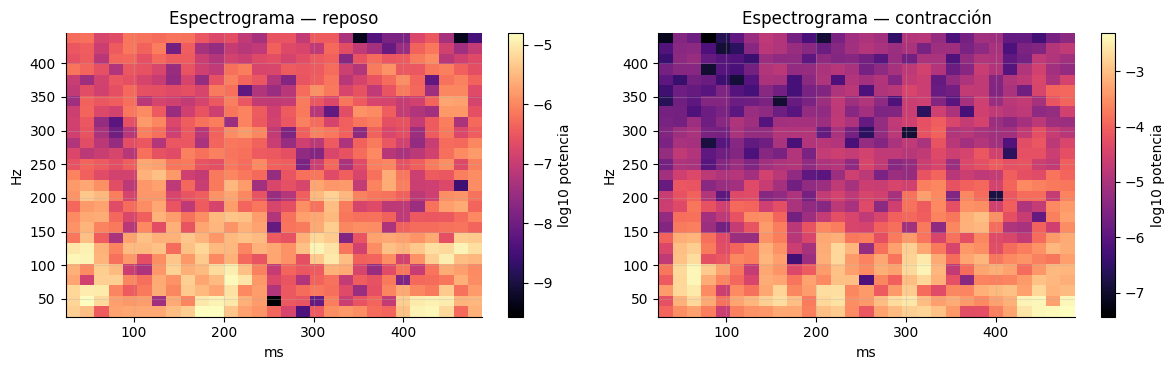

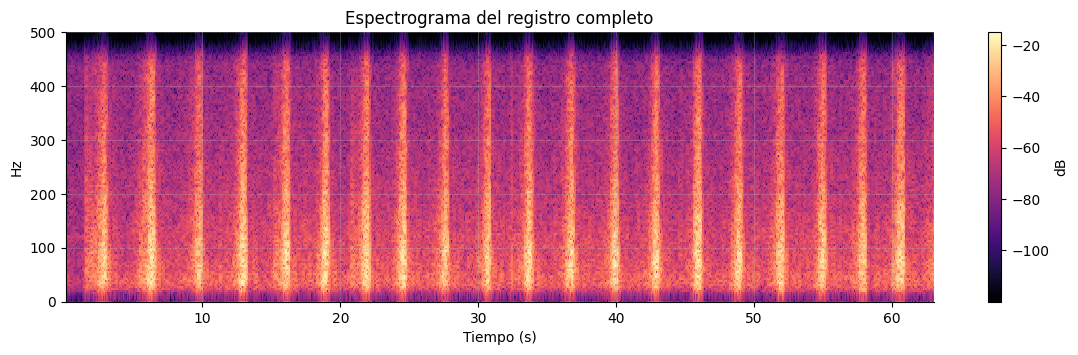

In [ ]:
# Ventanas más largas (500 ms) para que el espectrograma tenga suficientes columnas
VENTANA_CNN_MS = 500
win_cnn, ini_cnn = crear_ventanas(emg_prueba_f, FS, VENTANA_CNN_MS, 0.5)
n_cnn = win_cnn.shape[1]
frac = np.array([mascara_activa[i:i+n_cnn].mean() for i in ini_cnn])
lab_cnn = np.where(frac >= 0.8, 1, np.where(frac <= 0.05, 0, -1))
ciclo_cnn = np.clip(np.where(lab_cnn == 0,
                             np.searchsorted(inicios_contr, ini_cnn, side="left"),
                             np.searchsorted(inicios_contr, ini_cnn + n_cnn//2, side="right") - 1),
                    0, len(contracciones) - 1)
ok = lab_cnn >= 0
win_cnn, lab_cnn, ciclo_cnn = win_cnn[ok], lab_cnn[ok], ciclo_cnn[ok]

def espectrograma(x, fs=FS, nperseg=64, noverlap=48):
    f, t, S = signal.stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap, boundary=None)
    banda = (f >= 20) & (f <= 450)
    return f[banda], t, np.log10(np.abs(S[banda])**2 + 1e-10)

f_s, t_s, _ = espectrograma(win_cnn[0])
imagenes = np.stack([espectrograma(w)[2] for w in win_cnn]).astype(np.float32)
print(f"Imágenes: {imagenes.shape} (muestras, frecuencias, tiempos) | "
      f"reposo: {(lab_cnn==0).sum()}  contracción: {(lab_cnn==1).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, clase, nombre in zip(ax, [0, 1], ["reposo", "contracción"]):
    i = np.flatnonzero(lab_cnn == clase)[2]
    im = a.pcolormesh(t_s*1000, f_s, imagenes[i], shading="auto", cmap="magma")
    a.set_title(f"Espectrograma — {nombre}"); a.set_xlabel("ms"); a.set_ylabel("Hz")
    plt.colorbar(im, ax=a, label="log10 potencia")
plt.tight_layout(); plt.show()

# Espectrograma del registro completo: la "película" tiempo-frecuencia
f_full, t_full, S_full = signal.spectrogram(emg_prueba_f, fs=FS, nperseg=256, noverlap=192)
plt.figure(figsize=(14, 3.5))
plt.pcolormesh(t_full, f_full, 10*np.log10(S_full + 1e-12), shading="auto", cmap="magma")
plt.ylim(0, 500); plt.xlabel("Tiempo (s)"); plt.ylabel("Hz"); plt.colorbar(label="dB")
plt.title("Espectrograma del registro completo"); plt.show()

📘 **Explicación.** Para la CNN se usaron ventanas más largas (500 ms) y se convirtió cada una en un **espectrograma**: una imagen de **27 frecuencias × 29 instantes de tiempo**. Resultaron **185 imágenes** (106 de reposo y 79 de contracción), tras descartar las transiciones.

- **Espectrogramas individuales:** la escala de color de la contracción llega a valores más altos (≈ −3) que la del reposo (≈ −5). En la escala logarítmica eso equivale a unas **100 veces más potencia**. La CNN debe aprender a reconocer esa diferencia.
- **Espectrograma del registro completo:** se ven unas **20 franjas verticales brillantes**, una por contracción. Cada franja se extiende desde las frecuencias bajas hasta las altas, pero es más intensa abajo.

### 7.3 Arquitectura de la CNN
Una red pequeña (≈ 1 300 parámetros) es suficiente para esta tarea y entrena en segundos en CPU:

```
Entrada (1 × F × T)
 → Conv2D 3×3, 8 filtros  → BatchNorm → ReLU → MaxPool 2×2      ← aprende patrones locales tiempo-frecuencia
 → Conv2D 3×3, 16 filtros → BatchNorm → ReLU → MaxPool 2×2      ← combina patrones en estructuras mayores
 → Global Average Pooling                                         ← resume cada mapa en un número
 → Lineal (16 → 2)                                                ← clasificador
```

Las capas convolucionales hacen el papel de **extractor de características**; la última capa lineal es el **clasificador**. Observa la analogía con el Bloque 6.

Usamos la **misma división por grupos** que antes para que la comparación sea justa. Cada ciclo entra completo a entrenamiento o a prueba, y la normalización se calcula solo con entrenamiento.

In [ ]:
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch")

if TORCH_OK:
    torch.manual_seed(0)

    class CNNEspectrograma(nn.Module):
        def __init__(self, n_clases=2):
            super().__init__()
            self.extractor = nn.Sequential(
                nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.AdaptiveAvgPool2d(1),
            )
            self.clasificador = nn.Linear(16, n_clases)
        def forward(self, x):
            return self.clasificador(self.extractor(x).flatten(1))

    def entrenar_cnn(X_tr, y_tr, X_te, epocas=40, lr=1e-2):
        mu, sd = X_tr.mean(), X_tr.std()
        Xtr = torch.tensor((X_tr - mu) / sd).unsqueeze(1)
        Xte = torch.tensor((X_te - mu) / sd).unsqueeze(1)
        ytr = torch.tensor(y_tr, dtype=torch.long)
        modelo = CNNEspectrograma()
        opt = torch.optim.Adam(modelo.parameters(), lr=lr)
        perdida_fn = nn.CrossEntropyLoss()
        historial = []
        for _ in range(epocas):
            modelo.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(Xtr), 32):
                idx = perm[i:i+32]
                if len(idx) < 2:      # BatchNorm necesita al menos 2 muestras por lote
                    continue
                opt.zero_grad()
                loss = perdida_fn(modelo(Xtr[idx]), ytr[idx])
                loss.backward(); opt.step()
            historial.append(loss.item())
        modelo.eval()
        with torch.no_grad():
            pred = modelo(Xte).argmax(1).numpy()
        return pred, historial, modelo

    print("Parámetros entrenables:",
          sum(p.numel() for p in CNNEspectrograma().parameters() if p.requires_grad))

Parámetros entrenables: 1330


📘 **Explicación.** Se definió la red neuronal. Tiene **1 330 parámetros entrenables**, los números que la red ajusta durante el entrenamiento. Es una red muy pequeña (las CNN para imágenes suelen tener millones), elegida a propósito porque hay pocos datos.

Pliegue 1: exactitud balanceada = 0.955
Pliegue 2: exactitud balanceada = 1.000
Pliegue 3: exactitud balanceada = 1.000
Pliegue 4: exactitud balanceada = 0.967
Pliegue 5: exactitud balanceada = 0.969

CNN (espectrograma) — GroupKFold: 0.978 ± 0.019


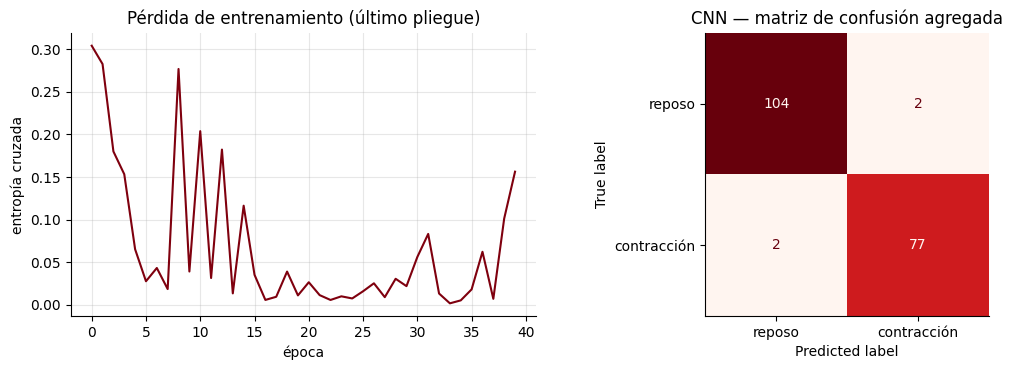

In [ ]:
if TORCH_OK:
    resultados_cnn, y_true_all, y_pred_all = [], [], []
    for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(imagenes, lab_cnn, ciclo_cnn)):
        pred, hist, modelo_cnn = entrenar_cnn(imagenes[tr], lab_cnn[tr], imagenes[te])
        resultados_cnn.append(balanced_accuracy_score(lab_cnn[te], pred))
        y_true_all += list(lab_cnn[te]); y_pred_all += list(pred)
        print(f"Pliegue {k+1}: exactitud balanceada = {resultados_cnn[-1]:.3f}")
    print(f"\nCNN (espectrograma) — GroupKFold: {np.mean(resultados_cnn):.3f} ± {np.std(resultados_cnn):.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist, color=COLOR_UPCH); ax[0].set_title("Pérdida de entrenamiento (último pliegue)")
    ax[0].set_xlabel("época"); ax[0].set_ylabel("entropía cruzada")
    ConfusionMatrixDisplay(confusion_matrix(y_true_all, y_pred_all),
                           display_labels=["reposo", "contracción"]).plot(ax=ax[1], cmap="Reds", colorbar=False)
    ax[1].grid(False); ax[1].set_title("CNN — matriz de confusión agregada")
    plt.tight_layout(); plt.show()

📘 **Explicación.** La CNN se entrenó 5 veces, una por pliegue de GroupKFold, con la misma lógica de división por ciclos.

- **Resultados por pliegue:** 0.955, 1.000, 1.000, 0.967 y 0.969. **Promedio: 0.978 ± 0.019.**
- **Matriz de confusión** (los 5 pliegues juntos): de 106 reposos, 104 bien y 2 mal; de 79 contracciones, 77 bien y 2 mal. Solo **4 errores en 185 imágenes**.
- **Curva de pérdida** (último pliegue): baja rápido en las primeras 5 épocas, pero luego tiene **saltos bruscos** (hasta ~0.28 en la época 8) y **vuelve a subir al final** (~0.15 en la época 40). Indica un entrenamiento inestable. *(Conceptual.)* Una tasa de aprendizaje menor (`lr = 1e-3`) o detener el entrenamiento cuando la pérdida es mínima probablemente lo estabilizaría.

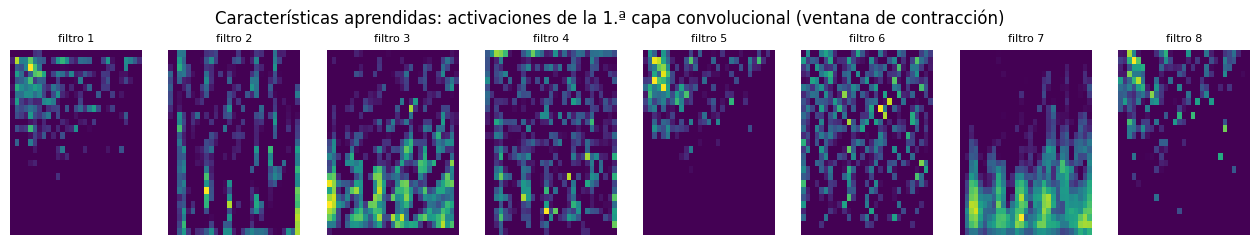

In [ ]:
# ¿Qué "mira" la red? Mapas de activación de los 8 filtros de la primera capa
if TORCH_OK:
    i = np.flatnonzero(lab_cnn == 1)[2]
    x_in = torch.tensor((imagenes[i] - imagenes.mean()) / imagenes.std()).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        mapas = modelo_cnn.extractor[:3](x_in)[0].numpy()
    fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    for k in range(8):
        ax[k].imshow(mapas[k], origin="lower", aspect="auto", cmap="viridis")
        ax[k].set_title(f"filtro {k+1}", fontsize=8); ax[k].axis("off")
    plt.suptitle("Características aprendidas: activaciones de la 1.ª capa convolucional (ventana de contracción)", y=1.05)
    plt.show()

📘 **Explicación.** Cada recuadro muestra cómo responde uno de los 8 filtros de la primera capa ante una ventana de contracción. Las zonas claras indican dónde el filtro "se activa". En cada recuadro, abajo están las frecuencias bajas y arriba las altas.

Los filtros **no responden todos igual**. Por ejemplo, el filtro 7 se activa sobre todo en la parte baja (frecuencias bajas), mientras que los filtros 1 y 5 lo hacen en la parte superior. Cada filtro aprendió por sí solo a fijarse en una zona o patrón distinto del espectrograma: son **características aprendidas**, en lugar de diseñadas por nosotros. A diferencia del RMS o la MDF, no tienen un nombre ni una fórmula fisiológica clara, y esa es la pérdida de **interpretabilidad** del deep learning.

> ❓ **Preguntas de verificación**
> 1. ¿La CNN superó al LDA con características clásicas? Considerando el costo y la interpretabilidad, ¿cuál elegirías para esta tarea?
> 2. Aquí tenemos ~200 imágenes de **un solo sujeto**. ¿Qué pasaría con la CNN si probáramos en otra persona?
> 3. Otra opción es una **1D-CNN** sobre la señal cruda de cada ventana, sin STFT. ¿Qué ventaja y qué desventaja tendría?

✅ **Respuestas**

1. **Numéricamente, un poco:** CNN **0.978 ± 0.019**, LDA **0.966 ± 0.023**, SVM 0.972 ± 0.016. Pero la diferencia es **menor que la variación entre pliegues**, así que no se puede afirmar que sea mejor. Además, la comparación no es exacta: la CNN usó ventanas de 500 ms (185 muestras) y el LDA de 250 ms (444 muestras). El dato decisivo es que **un solo umbral en RMS obtuvo 0.991**, el mejor resultado de todo el laboratorio, sin entrenamiento costoso y con total interpretabilidad. **Para esta tarea, el umbral en RMS (o el LDA) es la mejor elección.**
2. *(Respuesta conceptual; con estos datos no se puede medir.)* No sabemos cuánto bajaría, porque solo hay un sujeto. Pero hay razones para esperar que empeore. La amplitud y el espectro de la sEMG dependen de la anatomía, del tejido adiposo y de la posición de los electrodos, que cambian entre personas. Con solo 185 imágenes, la red pudo aprender detalles propios de este registro. Para comprobarlo habría que grabar a varias personas y evaluar **dividiendo por sujeto**.
3. *(Respuesta conceptual.)*
   - **Ventaja:** la red aprendería directamente de la señal, sin que tengamos que elegir los parámetros de la STFT (tamaño de ventana, solapamiento), que imponen un compromiso entre resolución en tiempo y en frecuencia.
   - **Desventaja:** sin la STFT la red tiene que descubrir por sí sola la estructura en frecuencia. Eso suele requerir **más datos y más parámetros**, justo lo que aquí escasea.

---
# 8. Ejercicios

## Ejercicio 1 — Selección de características y tamaño de ventana (obligatorio)
1. Repite la extracción de características con ventanas de **100 ms** y **500 ms** (además de 250 ms).
2. Para cada tamaño, calcula la **razón de Fisher** de RMS, ZC, Curtosis y MDF.
3. Entrena un **LDA con solo las 3 características más discriminantes** (según Fisher) usando `GroupKFold`.
4. Elimina las ventanas saturadas y repite. ¿Cambia el resultado? ¿Cambia la curtosis promedio de la contracción?

**Entrega:** tabla (tamaño de ventana × característica) y una conclusión de 5–8 líneas.

*Completa las líneas marcadas con `# TODO`.*

In [ ]:

# ===== EJERCICIO 1 — SOLUCIÓN =====
def tabla_caracteristicas(x, ventana_ms, solap=0.5):
    w, ini = crear_ventanas(x, FS, ventana_ms, solap)
    n = w.shape[1]
    fr = np.array([mascara_activa[i:i+n].mean() for i in ini])
    et = np.where(fr >= 0.8, "contraccion", np.where(fr <= 0.05, "reposo", "transicion"))
    d = pd.DataFrame([extraer_caracteristicas(v) for v in w])
    d["etiqueta"] = et
    d["ciclo"] = np.clip(np.where(et == "reposo",
                                  np.searchsorted(inicios_contr, ini, side="left"),
                                  np.searchsorted(inicios_contr, ini + n//2, side="right") - 1),
                         0, len(contracciones) - 1)
    d["saturada"] = [sat_prueba[i:i+n].any() for i in ini]
    d["saturada_corr"] = [((adc_prueba[i:i+n] <= 0) | (adc_prueba[i:i+n] >= 2**N_BITS - 2)).any() for i in ini]
    return d[d.etiqueta != "transicion"]

def razon_fisher(d, cols):
    a, b = d[d.etiqueta == "reposo"], d[d.etiqueta == "contraccion"]
    return (a[cols].mean() - b[cols].mean())**2 / (a[cols].var() + b[cols].var())

# Paso 1 y 2: tabla de Fisher por tamaño de ventana
tablas = {vm: tabla_caracteristicas(emg_prueba_f, vm) for vm in [100, 250, 500]}
print("Número de ventanas usadas (sin transiciones):", {f"{k} ms": len(v) for k, v in tablas.items()})
display(pd.DataFrame({f"{vm} ms": razon_fisher(d, ["RMS", "ZC", "Curtosis", "MDF"])
                      for vm, d in tablas.items()}).round(2))

# Paso 3: top-3 por Fisher (250 ms) y LDA con GroupKFold
d250 = tablas[250]
top3 = razon_fisher(d250, CARACTERISTICAS).nlargest(3).index.tolist()
print("Top-3 características (250 ms):", top3)

def evaluar_lda(d, cols):
    yy = (d.etiqueta == "contraccion").astype(int).values
    s = cross_val_score(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
                        d[cols].values, yy, cv=GroupKFold(5), groups=d.ciclo.values, scoring="balanced_accuracy")
    return s.mean(), s.std()

filas = []
for nombre, d in [("Todas las ventanas", d250),
                  ("Sin ventanas saturadas (criterio original)", d250[~d250.saturada]),
                  ("Sin ventanas saturadas (criterio corregido)", d250[~d250.saturada_corr])]:
    m, s = evaluar_lda(d, top3)
    curt = d.loc[d.etiqueta == "contraccion", "Curtosis"].mean()
    filas.append({"Conjunto": nombre, "N ventanas": len(d),
                  "Contracciones": int((d.etiqueta == "contraccion").sum()),
                  "LDA top-3 (exactitud balanceada)": f"{m:.3f} ± {s:.3f}",
                  "Curtosis media en contracción": round(curt, 2)})
display(pd.DataFrame(filas))


Número de ventanas usadas (sin transiciones): {'100 ms': 1207, '250 ms': 444, '500 ms': 185}


,100 ms,250 ms,500 ms
RMS,0.88,1.27,2.52
ZC,2.72,5.21,9.85
Curtosis,0.00,0.05,0.09
MDF,0.07,0.24,1.02


Top-3 características (250 ms): ['SSC', 'WAMP', 'ZC']


,Conjunto,N ventanas,Contracciones,LDA top-3 (exactitud balanceada),Curtosis media en contracción
0,Todas las ventanas,444,188,0.953 ± 0.031,3.02
1,Sin ventanas saturadas (criterio original),392,136,0.941 ± 0.032,3.72
2,Sin ventanas saturadas (criterio corregido),376,120,0.936 ± 0.036,3.73


✅ **Respuesta — Ejercicio 1**

**Tabla de la razón de Fisher según el tamaño de ventana:**

| | 100 ms (1 207 ventanas) | 250 ms (444) | 500 ms (185) |
|---|---|---|---|
| RMS | 0.88 | 1.27 | 2.52 |
| ZC | 2.72 | 5.21 | 9.85 |
| Curtosis | 0.00 | 0.05 | 0.09 |
| MDF | 0.07 | 0.24 | 1.02 |

**Clasificación con LDA y las 3 mejores características (SSC, WAMP, ZC), en ventanas de 250 ms:**

| Conjunto | Ventanas de contracción | Exactitud balanceada | Curtosis media (contracción) |
|---|---|---|---|
| Todas las ventanas | 188 | 0.953 ± 0.031 | 3.02 |
| Sin saturadas (criterio original) | 136 | 0.941 ± 0.032 | 3.72 |
| Sin saturadas (criterio corregido, incluye 1022) | 120 | 0.936 ± 0.036 | 3.73 |

**Conclusión:**

- **El tamaño de ventana importa:** al pasar de 100 a 500 ms, la razón de Fisher aumenta en las cuatro características. Una ventana más larga promedia más muestras, así que sus estimaciones son menos ruidosas y las clases se separan mejor. La **MDF es la más beneficiada**: se multiplica por ~14 (0.07 → 1.02), porque estimar un espectro con pocas muestras es muy impreciso.
- **El precio de la ventana larga** es menos ventanas (1 207 → 185) y peor resolución temporal: una decisión cada 500 ms en lugar de cada 100 ms.
- **La curtosis no separa las clases con ningún tamaño** (≤ 0.09).
- **Las 3 características de Fisher (SSC, WAMP, ZC)** con LDA dan **0.953**. Es algo menos que las 15 juntas (0.966) y bastante menos que un solo umbral en RMS (0.991). Ser la mejor característica *individual* según Fisher no garantiza el mejor conjunto para un clasificador.
- **Excluir las ventanas saturadas** baja ligeramente la exactitud (0.953 → 0.941 → 0.936), aunque dentro de la variación entre pliegues. Con ello se pierden entre 52 y 68 de las 188 ventanas de contracción, precisamente las más intensas. En cambio, la **curtosis media de la contracción sube de 3.02 a ~3.7**, lo que confirma que la saturación la estaba reduciendo.

## Ejercicio 2 — ¿Hay fatiga a lo largo de las contracciones? (tarea)
La teoría predice que con la fatiga **la MDF disminuye** y **el RMS aumenta**.

1. Para cada contracción detectada, calcula RMS, MNF y MDF sobre **toda la contracción**. Descarta 100 ms al inicio y al final para evitar las transiciones.
2. Grafica cada característica en función del número de contracción y ajusta una recta (`np.polyfit`).
3. Calcula la pendiente de la MDF y su correlación de Spearman con el número de contracción (`scipy.stats.spearmanr`).
4. Discute: ¿hay evidencia de fatiga? ¿Qué limitaciones tiene este protocolo para concluirlo? Piensa en la intensidad no controlada, en pocas repeticiones y en la saturación.

Opcional, para quien quiera profundizar en deep learning: entrena la CNN del Bloque 7 con ventanas de 250 ms y compara.

Contracciones analizadas: 21 | duración del registro: 63.15 s


,contraccion,inicio_s,fin_s,RMS,MNF,MDF
0,1,1.49,3.34,0.274,92.560,78.125
1,2,5.28,6.99,0.435,93.487,85.938
2,3,8.98,10.29,0.235,87.612,70.312
3,4,12.16,13.34,0.491,87.636,70.312
4,5,15.16,16.83,0.373,95.631,85.938
5,6,18.22,19.65,0.414,94.317,85.938
6,7,20.70,22.31,0.346,94.792,78.125
7,8,23.89,25.18,0.441,92.724,78.125
8,9,26.75,27.99,0.318,97.508,93.750
9,10,29.96,31.12,0.325,91.400,78.125


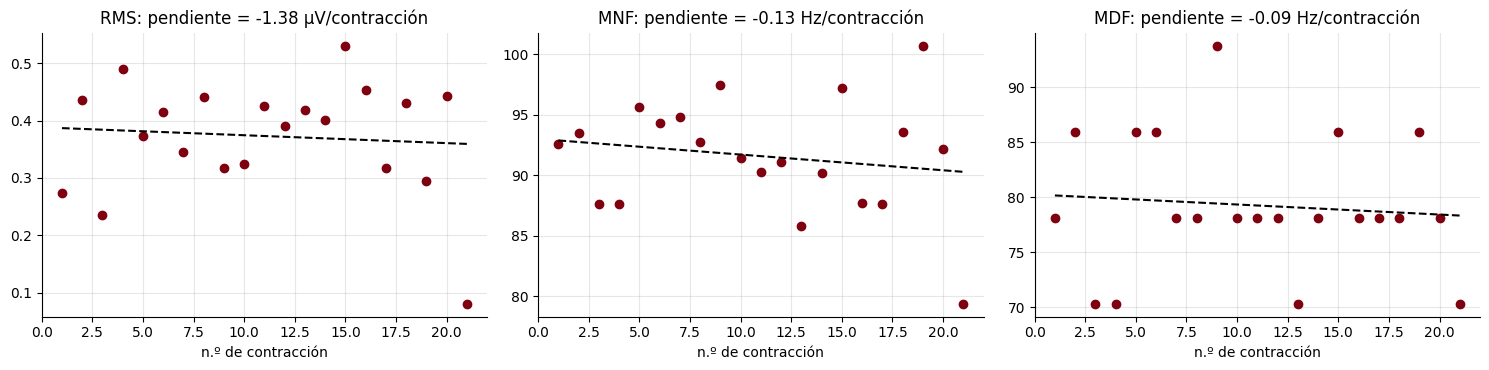

Con todas las contracciones:


,Característica,Pendiente,rho de Spearman,p-valor
0,RMS,-1.38 µV/contr.,0.05,0.819
1,MNF,-0.13 Hz/contr.,-0.12,0.610
2,MDF,-0.09 Hz/contr.,-0.09,0.698


Sin la última contracción:


,Característica,Pendiente,rho de Spearman,p-valor
0,RMS,3.03 µV/contr.,0.22,0.352
1,MNF,0.04 Hz/contr.,0.02,0.930
2,MDF,0.04 Hz/contr.,0.03,0.889


In [ ]:

# ===== EJERCICIO 2 — SOLUCIÓN =====
from scipy.stats import spearmanr

MARGEN = int(0.1 * FS)
filas = []
for k, (s, e) in enumerate(contracciones):
    seg = emg_prueba_f[s + MARGEN : e - MARGEN]
    if len(seg) < 0.3 * FS:
        continue
    c = extraer_caracteristicas(seg)
    filas.append({"contraccion": k + 1, "inicio_s": round(s/FS, 2), "fin_s": round(e/FS, 2),
                  "RMS": c["RMS"], "MNF": c["MNF"], "MDF": c["MDF"]})
df_fatiga = pd.DataFrame(filas)
print(f"Contracciones analizadas: {len(df_fatiga)} | duración del registro: {len(emg_prueba_f)/FS:.2f} s")
display(df_fatiga.round(3))

unidades = {"RMS": ("µV", 1000), "MNF": ("Hz", 1), "MDF": ("Hz", 1)}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
resumen = []
for a, nombre in zip(ax, ["RMS", "MNF", "MDF"]):
    xk, yk = df_fatiga["contraccion"], df_fatiga[nombre]
    pend, inter = np.polyfit(xk, yk, 1)
    rho, p = spearmanr(xk, yk)
    u, esc = unidades[nombre]
    a.plot(xk, yk, "o", color=COLOR_UPCH); a.plot(xk, pend*xk + inter, "k--")
    a.set_title(f"{nombre}: pendiente = {pend*esc:.2f} {u}/contracción"); a.set_xlabel("n.º de contracción")
    resumen.append({"Característica": nombre, f"Pendiente": f"{pend*esc:.2f} {u}/contr.",
                    "rho de Spearman": round(rho, 2), "p-valor": round(p, 3)})
plt.tight_layout(); plt.show()
print("Con todas las contracciones:"); display(pd.DataFrame(resumen))

# Sensibilidad: repetir sin la última contracción (comprobar en la tabla si termina junto con el registro)
d2 = df_fatiga.iloc[:-1]
res2 = []
for nombre in ["RMS", "MNF", "MDF"]:
    pend = np.polyfit(d2["contraccion"], d2[nombre], 1)[0]
    rho, p = spearmanr(d2["contraccion"], d2[nombre])
    u, esc = unidades[nombre]
    res2.append({"Característica": nombre, "Pendiente": f"{pend*esc:.2f} {u}/contr.",
                 "rho de Spearman": round(rho, 2), "p-valor": round(p, 3)})
print("Sin la última contracción:"); display(pd.DataFrame(res2))


✅ **Respuesta — Ejercicio 2**

**Resultados (21 contracciones):**

| Característica | Pendiente | ρ de Spearman | p-valor |
|---|---|---|---|
| RMS | −1.38 µV/contracción | 0.05 | 0.819 |
| MNF | −0.13 Hz/contracción | −0.12 | 0.610 |
| MDF | −0.09 Hz/contracción | −0.09 | 0.698 |

**¿Hay evidencia de fatiga? No.**

- Si hubiera fatiga, la teoría espera que la MDF y la MNF **bajen** y que el RMS **suba** a lo largo de las contracciones.
- Las pendientes de MNF y MDF son negativas pero diminutas: −0.09 Hz por contracción equivale a unos −1.8 Hz en 20 contracciones, menos que el salto entre dos valores posibles de MDF (ver la limitación 2).
- Todas las correlaciones son cercanas a cero (|ρ| ≤ 0.12) y ningún p-valor se acerca a 0.05.
- El RMS no sube: su pendiente es incluso ligeramente negativa.

**Análisis de sensibilidad.** La tabla muestra que la **contracción 21 termina en 63.15 s, justo donde termina el registro**: quedó **cortada**, y por eso su RMS (0.080 mV) es muy inferior al resto (0.235–0.531 mV). Al quitarla, las pendientes cambian de signo: RMS +3.03 µV/contr. (ρ = 0.22, p = 0.352), MNF y MDF +0.04 Hz/contr. (ρ ≈ 0, p > 0.88). **La conclusión no cambia:** no hay tendencia. Pero el caso muestra que un solo dato anómalo puede invertir el signo de una pendiente.

**Limitaciones del protocolo para concluir sobre fatiga:**

1. **La intensidad no estuvo controlada:** el RMS varía entre 0.235 y 0.531 mV de una contracción a otra sin un patrón claro. Los cambios de esfuerzo mueven el RMS y el espectro y pueden ocultar una tendencia de fatiga.
2. **La resolución de la MDF es gruesa:** la MDF solo toma valores como 70.3, 78.1, 85.9 y 93.8 Hz, en saltos de **7.8 Hz**. Es la resolución de Welch con `nperseg = 128` a 1000 Hz (1000/128 = 7.8 Hz). Un desplazamiento pequeño por fatiga quedaría por debajo de ese escalón. Usar un `nperseg` mayor afinaría la resolución.
3. **El protocolo es corto y con descansos:** contracciones de ~1.2 s con unos ~1.9 s de reposo entre ellas, durante ~1 minuto. *(Conceptual.)* Es poco tiempo de esfuerzo, y las pausas permiten recuperarse; los protocolos de fatiga suelen usar contracciones **sostenidas** a una fuerza fija.
4. **Hay saturación** en las contracciones más intensas, lo que distorsiona amplitud y espectro.
5. **Es un solo sujeto y un solo registro**, así que no se puede generalizar.

---
# 9. Cierre y síntesis

### Lo que hicimos
| Etapa | Concepto clave |
|---|---|
| Fisiología | La sEMG es la suma de MUAPs; amplitud y espectro reflejan el reclutamiento y la frecuencia de disparo |
| Adquisición | Amplificación diferencial, Fs ≥ 2·f_max, conversión ADC → mV, **la saturación no se repara** |
| Preprocesamiento | Pasa-banda 20–450 Hz + notch 60 Hz, filtrado de fase cero |
| Segmentación | Envolvente RMS, umbral con reposo **en las mismas condiciones**, ventanas de 100–500 ms |
| Características | Amplitud (RMS, MAV), complejidad (WL, ZC, SSC, WAMP), estadísticas (curtosis, asimetría), espectrales (MNF, MDF) |
| Clasificación | Normalización dentro del pipeline, **validación por grupos** para evitar fuga |
| Deep learning | STFT → espectrograma → CNN que **aprende** sus características |

### Para pensar
- ¿Qué características usarías para una prótesis que debe decidir en menos de 300 ms?
- ¿Cómo cambiaría el análisis con **varios canales** (varios músculos) en lugar de uno?
- ¿Qué haría falta para que el modelo funcione en **otro sujeto**?

### Entregables
1. Este cuaderno ejecutado, con las preguntas de verificación respondidas en celdas de texto.
2. Ejercicio 1 completo (tabla y conclusión).
3. Ejercicio 2 (gráficas de RMS, MNF y MDF con su interpretación).
4. Archivo `caracteristicas_emg.csv` (se genera en la celda siguiente).

### Referencias recomendadas
- De Luca, C. J. (1997). *The use of surface electromyography in biomechanics.* Journal of Applied Biomechanics, 13(2), 135–163.
- Hermens, H. J., Freriks, B., Disselhorst-Klug, C., & Rau, G. (2000). *Development of recommendations for SEMG sensors and sensor placement procedures (SENIAM).* Journal of Electromyography and Kinesiology, 10(5), 361–374.
- Hudgins, B., Parker, P., & Scott, R. N. (1993). *A new strategy for multifunction myoelectric control.* IEEE Transactions on Biomedical Engineering, 40(1), 82–94.
- Phinyomark, A., Phukpattaranont, P., & Limsakul, C. (2012). *Feature reduction and selection for EMG signal classification.* Expert Systems with Applications, 39(8), 7420–7431.
- Atzori, M., Cognolato, M., & Müller, H. (2016). *Deep learning with convolutional neural networks applied to electromyography data: a resource for the classification of movements for prosthetic hands.* Frontiers in Neurorobotics, 10, 9.
- PLUX. *BITalino (r)evolution — EMG Sensor Datasheet* (fórmula de conversión de unidades).

✅ **Respuestas a "Para pensar"** *(conceptuales: se apoyan en lo observado, pero van más allá de estos datos)*

- **Prótesis con decisión en menos de 300 ms:** se necesitan características **rápidas de calcular y estables con ventanas cortas**. Las de amplitud y complejidad (RMS/MAV, WL, ZC, SSC, WAMP) cumplen ambas condiciones. En el Ejercicio 1, con 100 ms, ZC (2.72) y RMS (0.88) mantienen buena separación, mientras que la MDF casi no separa (0.07) y la curtosis nada (0.00). Las espectrales necesitan ventanas más largas para ser fiables.
- **Varios canales (varios músculos):** el vector de características se calcula **para cada canal** y se concatena (por ejemplo, 4 canales × 5 características = 20 valores por ventana). Eso permite distinguir gestos por **qué músculos** se activan y cuánto, no solo por si hay actividad. También abre la puerta a representar los canales como una imagen para una CNN.
- **Que el modelo funcione en otra persona:** hace falta
  1. grabar a **varios sujetos**;
  2. **normalizar la amplitud** (por ejemplo, respecto de la contracción máxima de cada persona, %MVC);
  3. estandarizar la colocación de electrodos (SENIAM);
  4. evaluar con **validación por sujeto** (entrenar con unos y probar con otros).

  Este laboratorio mostró que hasta el umbral de reposo cambia entre registros del **mismo** sujeto (8.9 µV vs 43.2 µV), así que entre personas las diferencias serán mayores.

In [ ]:
df.to_csv("caracteristicas_emg.csv", index=False)
print("Archivo generado: caracteristicas_emg.csv", df.shape)
if EN_COLAB:
    from google.colab import files
    files.download("caracteristicas_emg.csv")

Archivo generado: caracteristicas_emg.csv (504, 19)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📘 **Explicación.** Se guardó la matriz de características en `caracteristicas_emg.csv`: **504 filas** (ventanas) × **19 columnas**, que son el tiempo de inicio, las 15 características, la etiqueta, el ciclo y la marca de saturación. En Colab, el archivo se descargó automáticamente.